<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">

# <span style="color:#2B2B2B;">**Deep Learning - Group Project**</span>

# <span style="color:#D4A017;">**"Tiny ImageNet Classification"**</span>

### <span style="color:#2B2B2B;">**Group XX**</span>

- **Ana Carolina D'Água** — 20241773
- **Beatriz Calisto** — 20241746
- **Francisca Teixeira** — 20241702
- **João Panizzutti** — [student number]
- **Margarida Pereira** — 20241777

<br>

#### <span style="color:#2B2B2B;">Bachelor's Degree in Data Science — Teachers: [Names] — 2026/27</span>

</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">

<h4 style="color:#2B2B2B;"><b>Table of contents</b></h4>

**0. Introduction**

**PART I – Exploratory Data Analysis & Data-Quality Assessment**\
**1. Setup and Loading of the Data**\
**2. Metadata Integrity**
<ul style="margin-top:-10px;">

   2.1. Missing Values \
   2.2. Duplicated Filenames \
   2.3. Consistency Between <code>class_id</code> and <code>description</code> \
   2.4. CSV vs. Image Folder
</ul>

**3. Class Distribution**\
**4. Image-Level Integrity**\
**5. Duplicate Images**\
**6. Image-Quality Issues**
<ul style="margin-top:-10px;">

   6.1. Computing Quality Scores \
   6.2. Heavy Colour Noise \
   6.3. Blur \
   6.4. Grayscale-Looking RGB Images \
   6.5. Borders / Frames \
   6.6. Near-Constant Images \
   6.7. Exposure, Contrast and Colour Cast \
   6.8. Overlap and Distribution Across Classes
</ul>

**7. Visual Inspection**\
**8. Label Noise**
<ul style="margin-top:-10px;">

   8.1. Duplicates with Conflicting Labels \
   8.2. Label Noise Revealed by the File Order
</ul>

**9. Summary of Findings and Decisions**

**PART II – Preprocessing**\
**10. Applying the Data-Quality Decisions**\
**11. Label Encoding**\
**12. Train / Validation / Test Split**\
**13. Class Weights**\
**14. Image Input Pipeline**\
**15. Data Augmentation**\
**16. Preprocessing Summary**

**PART III – Modelling** *(to do)*\
**PART IV – Evaluation and Error Analysis** *(to do)*

</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">0. Introduction</h3>
</div>

**Project Context and Goal:** \
This project addresses a **multiclass image classification** problem using deep learning. The dataset is a subset of **Tiny ImageNet**, a reduced version of the ImageNet benchmark, containing **60,000 colour images of 64×64 pixels** distributed across **200 object classes** (e.g. *barn*, *lemon*, *pizza*, *pipe organ*). Each image is described in `labels.csv` by its filename, a WordNet class identifier (`class_id`) and a human-readable class name (`description`).

The goal of the project is to build a model that, given a new image, predicts which of the 200 classes it belongs to. Since the README explicitly states that the dataset **has not been cleaned or partitioned** for modelling, the data cannot be used as provided: problems such as class imbalance, degraded images, duplicates or incorrect labels may be present and would directly affect both training and evaluation.

This is why the data analysis comes first. Before choosing any architecture, we need to understand the data and identify its issues, since every later decision (how to split the data, which preprocessing to apply, which metrics to report and how to interpret errors) depends on what we find here.

This notebook is organised in four parts:
- **Part I – EDA & Data Quality:** check the metadata, analyse the class distribution, detect corrupted, duplicated and low-quality images, and collect evidence of label noise.
- **Part II – Preprocessing:** apply the data-quality decisions, encode the labels, create stratified train/validation/test partitions and build the image input pipeline.
- **Part III – Modelling:** baseline CNN, improved CNN and pre-trained models (transfer learning and fine-tuning).
- **Part IV – Evaluation:** metrics, comparison between approaches and error analysis.

**For each issue we follow the three steps of Class 3 – Detect, Investigate, Decide – and record how many cases there are, how they were detected and what we decide to do (and why). These records are summarised in Section 9 and feed the final report.**

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h2 style="color:#2B2B2B;"><b>PART I – Exploratory Data Analysis & Data-Quality Assessment</b></h2>
</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">1. Setup and Loading of the Data</h3>
</div>

First, we load the necessary libraries, fix the random seed for reproducibility and define the paths and helper functions used throughout the notebook.

In [1]:
import os
import random
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = "data"                                   # folder with images/ and labels.csv
IMG_DIR = os.path.join(DATA_DIR, "images")
LABELS_PATH = os.path.join(DATA_DIR, "labels.csv")
OUTPUT_DIR = "outputs"                              # CSVs produced by this notebook
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Colours used in the plots (same palette as the notebook)
GOLD, BROWN = "#D4A017", "#8B4513"

/opt/anaconda3/envs/MachineLearning/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def show_grid(filenames, titles=None, ncols=8, size=1.8, suptitle=None):
    """Display a grid of images from IMG_DIR, optionally with a title under each one."""
    filenames = list(filenames)
    titles = None if titles is None else list(titles)
    if len(filenames) == 0:
        print("No images to show.")
        return
    nrows = int(np.ceil(len(filenames) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.15))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < len(filenames):
            ax.imshow(Image.open(os.path.join(IMG_DIR, filenames[i])).convert("RGB"))
            if titles is not None:
                ax.set_title(str(titles[i])[:22], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    plt.show()

In [3]:
labels = pd.read_csv(LABELS_PATH)
labels.head()

,filename,class_id,description
0,image_000001.JPEG,n03042490,cliff dwelling
1,image_000002.JPEG,n02793495,barn
2,image_000003.JPEG,n02793495,barn
3,image_000004.JPEG,n02793495,barn
4,image_000005.JPEG,n02793495,barn


In [4]:
labels.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   filename     60000 non-null  str  
 1   class_id     60000 non-null  str  
 2   description  60000 non-null  str  
dtypes: str(3)
memory usage: 4.0 MB


In [5]:
labels.describe()

,filename,class_id,description
count,60000,60000,60000
unique,60000,200,200
top,image_000001.JPEG,n03854065,"organ, pipe organ"
freq,1,549,549


<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Data Overview:</h4>


<font color='#B8860B'>Structure:</font>

The metadata file contains **60,000 entries** and **3 columns**, all stored as strings:
1. **filename**: name of the image file inside `images/` (e.g. `image_000001.JPEG`).
2. **class_id**: WordNet identifier of the class (e.g. `n02793495`).
3. **description**: human-readable class name (e.g. `barn`).

Note that the project statement mentions a **numerical label** in the metadata, but this column is not present in the file provided. We create it ourselves in Section 11.

<font color='#B8860B'>First observations:</font>

- **No missing values**: all three columns have 60,000 non-null entries.
- **Unique filenames**: `filename` has 60,000 unique values, so there are no duplicated rows in the metadata.
- **200 classes**: there are 200 unique `class_id` values and 200 unique descriptions, matching the 200 classes of Tiny ImageNet. However, equal counts do **not** guarantee a one-to-one mapping between IDs and descriptions; this is verified in Section 2.3.
- **First sign of class imbalance**: the most frequent class is `n03854065` (*organ, pipe organ*) with **549 images**, almost twice the 300 images per class expected in a perfectly balanced dataset (60,000 / 200). The full distribution is analysed in Section 3.
- **Possible label noise**: `image_000001.JPEG` is labelled as *cliff dwelling*, but visually it shows a barn by the water. This is a first concrete example of a potential labelling error, investigated in Section 8.

<font color='#B8860B'>Decision:</font>

Since filenames are unique, `filename` could be used as the index. We keep it as a **regular column**, because it will be needed later to merge with per-image statistics, to build image paths and to feed the data pipeline. Keeping it as a column avoids repeated `reset_index()` calls.


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">2. Metadata Integrity</h3>
</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">2.1. Missing Values</h4>
</div>

We check both explicit missing values (`NaN`) and *hidden* ones: empty strings or strings containing only whitespace, which `isnull()` does not detect.

In [6]:
print("Explicit missing values (NaN):")
print(labels.isnull().sum(), "\n")

print("Hidden missing values (empty or whitespace-only strings):")
print((labels.apply(lambda col: col.str.strip()) == "").sum())

Explicit missing values (NaN):
filename       0
class_id       0
description    0
dtype: int64 

Hidden missing values (empty or whitespace-only strings):
filename       0
class_id       0
description    0
dtype: int64


<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">2.2. Duplicated Filenames</h4>
</div>

Are there duplicated rows or filenames? We also check after normalising case and whitespace, since `image_1.JPEG` and `image_1.jpeg ` would not be detected as duplicates otherwise.

In [7]:
print(f"Duplicated rows: {labels.duplicated().sum()}")
print(f"Duplicated filenames: {labels['filename'].duplicated().sum()}")
print(f"Duplicated filenames (normalised): {labels['filename'].str.strip().str.lower().duplicated().sum()}")

Duplicated rows: 0
Duplicated filenames: 0
Duplicated filenames (normalised): 0


<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">2.3. Consistency Between <code>class_id</code> and <code>description</code></h4>
</div>

Does each `class_id` map to exactly one `description` (and vice versa)? Are there formatting variants (case, extra spaces)?

In [8]:
desc_per_id = labels.groupby("class_id")["description"].nunique()
id_per_desc = labels.groupby("description")["class_id"].nunique()

print(f"class_id values with more than one description: {(desc_per_id > 1).sum()}")
print(f"descriptions with more than one class_id:      {(id_per_desc > 1).sum()}")

class_id values with more than one description: 0
descriptions with more than one class_id:      0


In [9]:
for col in ["class_id", "description"]:
    original = labels[col].nunique()
    normalised = labels[col].str.strip().str.lower().nunique()
    print(f"{col}: {original} unique values -> {normalised} after normalising case/whitespace")

class_id: 200 unique values -> 200 after normalising case/whitespace
description: 200 unique values -> 200 after normalising case/whitespace


<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">2.4. CSV vs. Image Folder</h4>
</div>

Does every filename in the CSV exist in `images/`, and vice versa? 

In [10]:
folder_files = {f for f in os.listdir(IMG_DIR) if not f.startswith(".")}
csv_files = set(labels["filename"])

missing_from_folder = csv_files - folder_files
missing_from_csv = folder_files - csv_files

print(f"Images in folder: {len(folder_files)}")
print(f"In CSV but missing from folder: {len(missing_from_folder)}")
print(f"In folder but not in CSV: {len(missing_from_csv)}")

Images in folder: 60000
In CSV but missing from folder: 0
In folder but not in CSV: 0


<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Key observations:</h4>


- **2.1 Missing values:** no missing values, neither explicit (`NaN`) nor hidden (empty or whitespace-only strings).
- **2.2 Duplicated filenames:** no duplicated rows or filenames, even after normalising case and whitespace.
- **2.3 `class_id` ↔ `description`:** one-to-one mapping between the 200 IDs and the 200 descriptions; no formatting variants. Comma-separated descriptions are WordNet synonyms (standard ImageNet format), not inconsistencies.
- **2.4 CSV vs. folder:** the 60,000 filenames in the CSV exactly match the 60,000 files in `images/`.

**Conclusion:** the metadata is structurally consistent. This does **not** mean the labels are correct – it only means the file is well-formed. Label correctness and image content are analysed in Sections 5–8.


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">3. Class Distribution</h3>
</div>

Since the metadata is consistent (Section 2), the class counts below are reliable.

In [11]:
class_counts = labels["description"].value_counts()

print(f"Number of classes: {class_counts.size}")
print(f"Min images per class: {class_counts.min()} ({class_counts.idxmin()})")
print(f"Max images per class: {class_counts.max()} ({class_counts.idxmax()})")
print(f"Median images per class: {class_counts.median():.0f}")
print(f"Mean images per class: {class_counts.mean():.0f}")
print(f"Imbalance ratio (max/min): {class_counts.max() / class_counts.min():.2f}")

Number of classes: 200
Min images per class: 108 (pizza, pizza pie)
Max images per class: 549 (organ, pipe organ)
Median images per class: 274
Mean images per class: 300
Imbalance ratio (max/min): 5.08


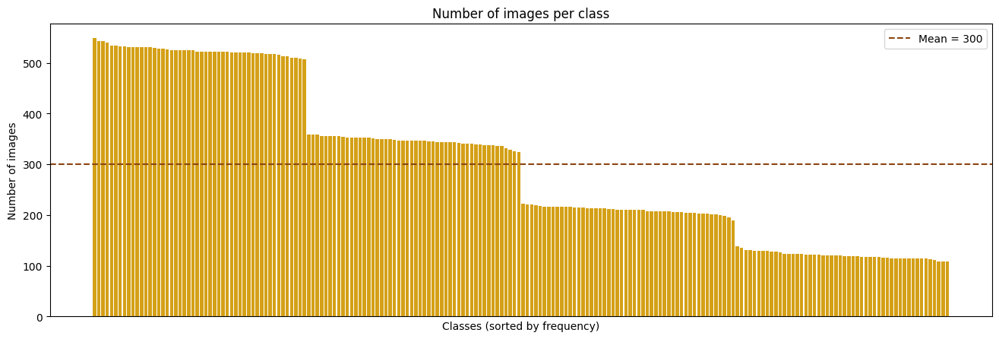

In [12]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(range(len(class_counts)), class_counts.values, color=GOLD)
ax.axhline(class_counts.mean(), color=BROWN, linestyle="--",
           label=f"Mean = {class_counts.mean():.0f}")
ax.set_xlabel("Classes (sorted by frequency)")
ax.set_ylabel("Number of images")
ax.set_title("Number of images per class")
ax.set_xticks([])
ax.legend()
plt.show()

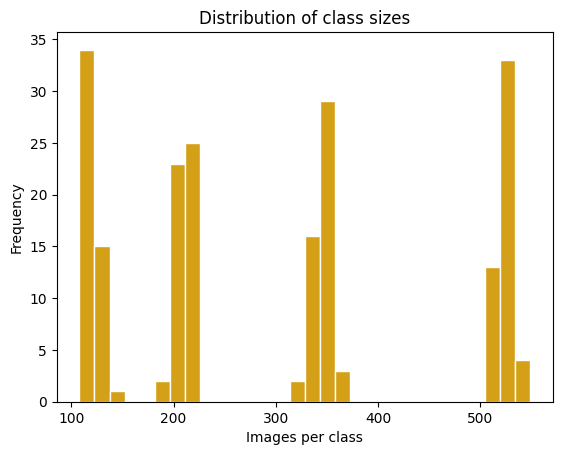

In [13]:
class_counts.plot(kind="hist", bins=30, color=GOLD, edgecolor="white",
                  title="Distribution of class sizes")
plt.xlabel("Images per class")
plt.show()

The histogram shows four separated groups of class sizes. We store each class's **size tier** so that we can later evaluate the model separately on small and large classes. The cut points fall in the empty gaps between the groups.

In [14]:
TIER_BINS = [0, 160, 260, 430, 10_000]
TIER_NAMES = ["small", "medium-low", "medium-high", "large"]

labels["class_size"] = labels["description"].map(class_counts)
labels["size_tier"] = pd.cut(labels["class_size"], bins=TIER_BINS, labels=TIER_NAMES)

tier_summary = (labels.groupby("size_tier", observed=True)
                      .agg(n_classes=("description", "nunique"),
                           n_images=("filename", "count"),
                           min_size=("class_size", "min"),
                           max_size=("class_size", "max")))
tier_summary["share_of_images"] = (tier_summary["n_images"] / len(labels)).round(3)
tier_summary

,n_classes,n_images,min_size,max_size,share_of_images
size_tier,,,,,
small,50,6016,108,138,0.100
medium-low,50,10502,190,223,0.175
medium-high,50,17288,324,359,0.288
large,50,26194,506,549,0.437


<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Analysis of the Class Distribution:</h4>


- **Observations**:
  - The 200 classes range from **108** (*pizza*) to **549** (*organ*) images, an **imbalance ratio of 5.08**. The median (274) is below the mean (300).
  - The imbalance is **step-wise, not gradual**: the classes form **four distinct tiers** (see `tier_summary` for the exact counts), with no classes in between.
  - This pattern does not look like natural imbalance (which would show a smooth long tail). It suggests the imbalance was **artificially introduced** when the dataset was prepared.

- **Implications**:
  - **Stratified splitting** is required so every class keeps its proportion in train, validation and test. Small classes will have few test images (~16 at a 15% test split), so per-class metrics for them will be noisy.
  - **Accuracy alone is misleading**, since the large classes dominate it: we also report **macro-F1**, which gives every class the same weight.
  - We will test **class weighting** during training to reduce bias towards the large classes.
  - The `size_tier` column will be used to evaluate **performance per tier** in the error analysis.


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">4. Image-Level Integrity</h3>
</div>

We open **every** image once and record its technical properties: can it be fully decoded? Is it 64×64? Which colour mode and file format does it have? `img.load()` forces full decoding, so truncated files are also detected, and `try/except` ensures a corrupted file does not stop the loop.

In [15]:
def inspect_image(path):
    """Return a dict with the basic technical properties of one image."""
    info = {"readable": False, "width": None, "height": None,
            "mode": None, "format": None, "error": None}
    try:
        with Image.open(path) as img:
            img.load()                       # forces full decoding (catches truncated files)
            info.update(readable=True, width=img.width, height=img.height,
                        mode=img.mode,       # 'RGB', 'L' (grayscale), 'RGBA', ...
                        format=img.format)   # real format, regardless of the extension
    except Exception as e:
        info["error"] = str(e)
    return info


records = []
for fname in tqdm(labels["filename"], desc="Inspecting images"):
    rec = inspect_image(os.path.join(IMG_DIR, fname))
    rec["filename"] = fname
    records.append(rec)

image_stats = pd.DataFrame(records)
image_stats.head()

Inspecting images: 100%|██████████| 60000/60000 [00:16<00:00, 3569.33it/s]


,readable,width,height,mode,format,error,filename
0,True,64,64,RGB,JPEG,None,image_000001.JPEG
1,True,64,64,RGB,JPEG,None,image_000002.JPEG
2,True,64,64,RGB,JPEG,None,image_000003.JPEG
3,True,64,64,RGB,JPEG,None,image_000004.JPEG
4,True,64,64,RGB,JPEG,None,image_000005.JPEG


In [16]:
print(image_stats["readable"].value_counts(), "\n")
print(image_stats[["width", "height"]].value_counts(), "\n")
print(image_stats["mode"].value_counts(), "\n")
print(image_stats["format"].value_counts())

readable
True    60000
Name: count, dtype: int64 

width  height
64     64        60000
Name: count, dtype: int64 

mode
RGB    59194
L        806
Name: count, dtype: int64 

format
JPEG    60000
Name: count, dtype: int64


**Grayscale-mode images:** are they concentrated in a few classes (suspicious) or spread across many (natural)?

In [17]:
gray_mode = image_stats[image_stats["mode"] == "L"].merge(labels, on="filename")

print(f"Grayscale-mode images: {len(gray_mode)} ({len(gray_mode) / len(labels):.1%})")
print(f"Classes with at least one grayscale image: {gray_mode['description'].nunique()} / 200\n")

gray_share = (gray_mode["description"].value_counts() / class_counts).dropna().sort_values(ascending=False)
print("Classes with the highest share of grayscale images:")
print(gray_share.head(10).round(3))

Grayscale-mode images: 806 (1.3%)
Classes with at least one grayscale image: 149 / 200

Classes with the highest share of grayscale images:
description
gondola                                                 0.061
sunglasses, dark glasses, shades                        0.057
tractor                                                 0.056
bow tie, bow-tie, bowtie                                0.055
barbershop                                              0.053
hourglass                                               0.051
oboe, hautboy, hautbois                                 0.050
fountain                                                0.049
bikini, two-piece                                       0.048
bannister, banister, balustrade, balusters, handrail    0.048
Name: count, dtype: float64


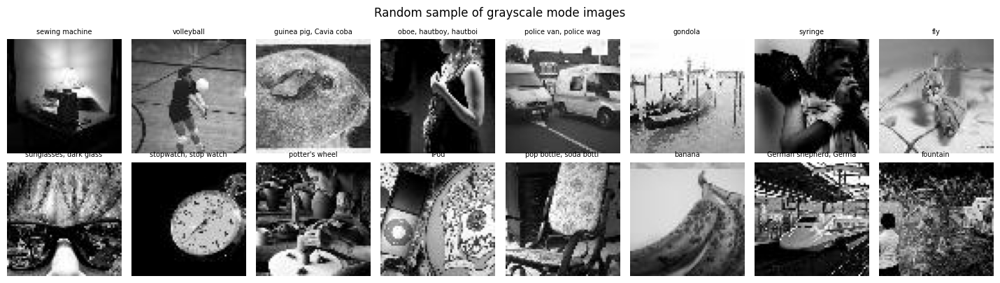

In [18]:
sample = gray_mode.sample(min(16, len(gray_mode)), random_state=SEED)
show_grid(sample["filename"], sample["description"], suptitle="Random sample of grayscale mode images")

<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Key observations:</h4>


- **All 60,000 images are readable**: no corrupted or truncated files.
- **All images are 64×64** and **all are genuine JPEG files**.
- **806 images (1.3%) are stored in grayscale** (`mode = L`), the rest are RGB.
  - They are spread across many classes (see the output above), with at most 26 per class (e.g. *bannister*, *oboe*, *pay-phone*) , objects that are often photographed in black and white. This matches the natural presence of grayscale photos in ImageNet rather than an artificial corruption.
  - **Decision:** keep them and **convert them to RGB** (replicating the single channel), since CNNs and pre-trained models expect a 3-channel input. Removing them would discard valid images, and grayscale images may also appear at test time.

**Limitation:** this section only detects *technical* issues. Visually degraded images (noise, blur, borders) still look like valid 64×64 RGB JPEGs ,for example `image_000003.JPEG` (heavy noise) passes all these checks. These are addressed in Section 6.


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">5. Duplicate Images</h3>
</div>

Unique filenames do not guarantee unique content. We compute, for every image, two fingerprints in a single pass (the same pass also computes the quality scores used in Section 6):

- **Exact duplicates:** MD5 hash of the pixel array – identical only if every pixel is identical.
- **Near duplicates:** a **difference hash (dHash)** – the image is reduced to 9×8 grayscale pixels and each bit records whether a pixel is brighter than its right neighbour. Slightly different versions of the same photo (re-compression, small colour changes) get the same hash.

Why it matters: a duplicate in both train and test is **data leakage** (the model is tested on an image it has already seen), and duplicates with **different labels** are direct evidence of label noise.

In [19]:
def dhash(img, hash_size=8):
    """Difference hash: 64-bit perceptual fingerprint, returned as a hex string."""
    small = np.asarray(img.convert("L").resize((hash_size + 1, hash_size), Image.BILINEAR), dtype=np.int16)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return np.packbits(bits).tobytes().hex()


def immerkaer_noise(channel):
    """Estimate of the noise standard deviation of one channel (Immerkaer, 1996)."""
    c = channel
    k = (c[:-2, :-2] - 2 * c[:-2, 1:-1] + c[:-2, 2:]
         - 2 * c[1:-1, :-2] + 4 * c[1:-1, 1:-1] - 2 * c[1:-1, 2:]
         + c[2:, :-2] - 2 * c[2:, 1:-1] + c[2:, 2:])
    h, w = c.shape
    return np.sqrt(np.pi / 2) * np.abs(k).sum() / (6 * (w - 2) * (h - 2))


def frame_sides(rgb, strip=2, gap=4, max_std=8.0, min_diff=25.0):
    """Number of image sides (0-4) with a uniform strip that differs from the content next to it."""
    sides = [(rgb[:strip], rgb[strip + gap: strip + 2 * gap]),                 # top
             (rgb[-strip:], rgb[-strip - 2 * gap: -strip - gap]),             # bottom
             (rgb[:, :strip], rgb[:, strip + gap: strip + 2 * gap]),          # left
             (rgb[:, -strip:], rgb[:, -strip - 2 * gap: -strip - gap])]       # right
    n = 0
    for edge, inner in sides:
        edge, inner = edge.reshape(-1, 3), inner.reshape(-1, 3)
        uniform = edge.std(axis=0).mean() < max_std
        different = np.abs(edge.mean(axis=0) - inner.mean(axis=0)).mean() > min_diff
        n += int(uniform and different)
    return n


def image_features(path):
    """Fingerprints (Section 5) and quality scores (Section 6) of one image."""
    with Image.open(path) as im:
        img = im.convert("RGB")
    rgb = np.asarray(img, dtype=np.float32)
    gray = rgb @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    ycbcr = np.asarray(img.convert("YCbCr"), dtype=np.float32)

    laplacian = (-4 * gray[1:-1, 1:-1] + gray[:-2, 1:-1] + gray[2:, 1:-1]
                 + gray[1:-1, :-2] + gray[1:-1, 2:])
    return {
        "md5": hashlib.md5(np.asarray(img).tobytes()).hexdigest(),
        "dhash": dhash(img),
        "laplacian_var": float(laplacian.var()),                          # low  -> blurry
        "chroma_noise": float((immerkaer_noise(ycbcr[..., 1])
                               + immerkaer_noise(ycbcr[..., 2])) / 2),    # high -> colour noise
        "luma_noise": float(immerkaer_noise(ycbcr[..., 0])),              # high -> grain noise
        "channel_diff": float(max(np.abs(rgb[..., 0] - rgb[..., 1]).mean(),
                                  np.abs(rgb[..., 1] - rgb[..., 2]).mean(),
                                  np.abs(rgb[..., 0] - rgb[..., 2]).mean())),  # ~0 -> looks grayscale
        "frame_sides": frame_sides(rgb),                                  # >0 -> border / frame
        "pixel_std": float(gray.std()),                                   # ~0 -> near-constant image
        "brightness": float(gray.mean()),
    }


feature_records = []
for fname in tqdm(labels["filename"], desc="Computing hashes and quality scores"):
    rec = image_features(os.path.join(IMG_DIR, fname))
    rec["filename"] = fname
    feature_records.append(rec)

image_stats = image_stats.merge(pd.DataFrame(feature_records), on="filename")
df = labels.merge(image_stats, on="filename")
df.head()

Computing hashes and quality scores: 100%|██████████| 60000/60000 [00:51<00:00, 1158.91it/s]


,filename,class_id,description,class_size,size_tier,readable,width,height,mode,format,error,md5,dhash,laplacian_var,chroma_noise,luma_noise,channel_diff,frame_sides,pixel_std,brightness
0,image_000001.JPEG,n03042490,cliff dwelling,117,small,True,64,64,RGB,JPEG,None,bdb3e1c1102870445e6025ec1b6d285d,f8801815232880c1,16468.228516,0.777045,21.292538,39.918213,0,53.243561,103.270111
1,image_000002.JPEG,n02793495,barn,520,large,True,64,64,RGB,JPEG,None,bef7bc759448f5850c113131d068687a,0283830768fcc6c3,10120.609375,0.805927,13.122086,82.007812,2,66.326775,143.568314
2,image_000003.JPEG,n02793495,barn,520,large,True,64,64,RGB,JPEG,None,71757479491311041c1458e55cd1a6b1,f0f4e498ca9490e8,15049.564453,15.730603,23.569957,27.010742,0,60.385910,90.851593
3,image_000004.JPEG,n02793495,barn,520,large,True,64,64,RGB,JPEG,None,808f4deb6bc2035c1b713678c0fb4d54,1406436162e6c94b,8983.633789,14.881638,17.390766,36.387207,0,81.917747,142.624786
4,image_000005.JPEG,n02793495,barn,520,large,True,64,64,RGB,JPEG,None,fc655abdb3950c67e2d0a5d5732a4267,60a01c0e06435161,5598.182617,0.229970,7.628729,16.049561,0,82.830620,151.556610


<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">5.1. Exact Duplicates</h4>
</div>

In [20]:
exact = df[df.duplicated("md5", keep=False)]
exact_groups = exact.groupby("md5")
exact_conflicting = exact_groups["class_id"].nunique()
exact_conflicting = exact_conflicting[exact_conflicting > 1].index

print(f"Images involved in exact duplicates: {len(exact)}")
print(f"Groups of exact duplicates: {exact['md5'].nunique()}")
print(f"Redundant copies (images that could be removed): {len(exact) - exact['md5'].nunique()}")
print(f"Groups with CONFLICTING labels: {len(exact_conflicting)} "
      f"({exact[exact['md5'].isin(exact_conflicting)].shape[0]} images)")
print("\nGroup sizes:")
print(exact_groups.size().value_counts().sort_index())

Images involved in exact duplicates: 12
Groups of exact duplicates: 6
Redundant copies (images that could be removed): 6
Groups with CONFLICTING labels: 6 (12 images)

Group sizes:
2    6
Name: count, dtype: int64


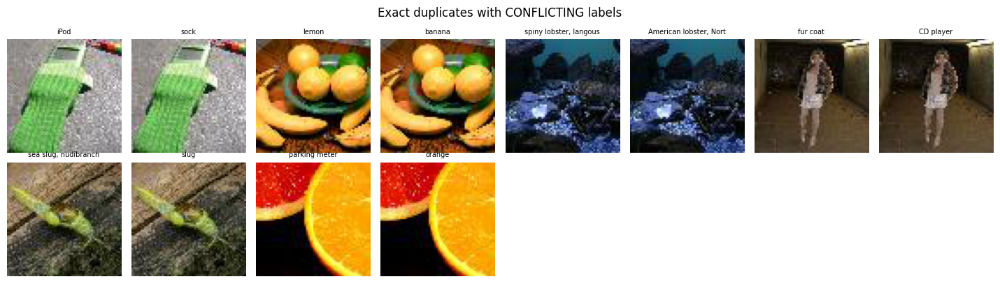

In [21]:
# Exact duplicates with conflicting labels
ex = exact[exact["md5"].isin(exact_conflicting[:8])].sort_values("md5")
show_grid(ex["filename"], ex["description"], suptitle="Exact duplicates with CONFLICTING labels")

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">5.2. Near Duplicates</h4>
</div>

Near duplicates are images with the same dHash but **different pixels**. Uniform images (e.g. completely blank) all share the same trivial hash, so those hashes are excluded from the grouping and handled in Section 6.6.

In [22]:
TRIVIAL_HASHES = {"0" * 16, "f" * 16}

df["dup_group"] = np.where(df["dhash"].isin(TRIVIAL_HASHES), None, df["dhash"])
near = df[df["dup_group"].notna() & df.duplicated("dup_group", keep=False)]

# to keep only groups that contain at least two DIFFERENT pixel arrays (otherwise they are exact duplicates)
near_only = near.groupby("dup_group").filter(lambda g: g["md5"].nunique() > 1)
near_conflicting = near_only.groupby("dup_group")["class_id"].nunique()
near_conflicting = near_conflicting[near_conflicting > 1].index

print(f"Images in near-duplicate groups (not exact): {len(near_only)}")
print(f"Near-duplicate groups: {near_only['dup_group'].nunique()}")
print(f"Groups with CONFLICTING labels: {len(near_conflicting)}")

Images in near-duplicate groups (not exact): 38
Near-duplicate groups: 13
Groups with CONFLICTING labels: 12


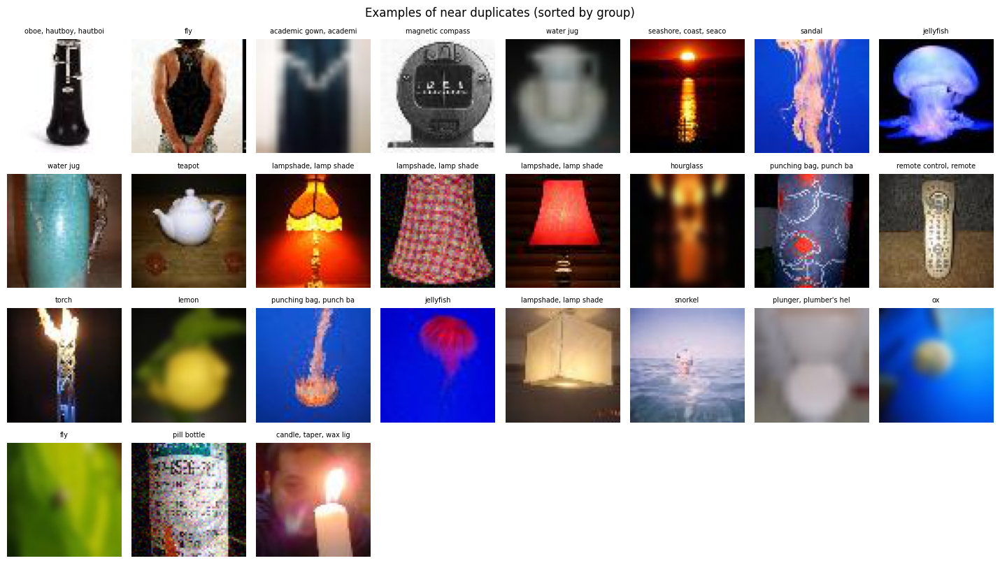

In [23]:
ex = near_only[near_only["dup_group"].isin(near_only["dup_group"].drop_duplicates().head(8))].sort_values("dup_group")
show_grid(ex["filename"], ex["description"], suptitle="Examples of near duplicates (sorted by group)")

In [24]:
# How different are the images inside each dHash group? (mean absolute pixel difference, 0-255)
def mean_pixel_diff(files):
    arrs = [np.asarray(Image.open(os.path.join(IMG_DIR, f)).convert("RGB"), dtype=np.float32) for f in files]
    return np.mean([np.abs(arrs[0] - a).mean() for a in arrs[1:]])

group_diff = near_only.groupby("dup_group")["filename"].apply(lambda s: mean_pixel_diff(list(s)))
print(group_diff.describe().round(1))

count     13.0
mean      74.9
std       23.1
min       41.4
25%       55.3
50%       71.1
75%       92.4
max      112.2
Name: filename, dtype: float64


*The grid and the pixel differences above show that the dHash groups are false positives, not real duplicates.*

<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Key observations:</h4>


<font color='#B8860B'>Detect</font>

- **Exact duplicates:** MD5 hash of the pixel array → **12 images in 6 groups of 2**.
- **Near duplicates:** dHash → 38 images in 13 groups.

<font color='#B8860B'>Investigate</font>

- **All 6 exact-duplicate groups have conflicting labels** – there is no duplicate with the same label. The same image was copied and given a different class, i.e. the duplicates were **injected as label noise**.
  - Some pairs are **visually similar classes** (*spiny lobster / American lobster*, *sea slug / slug*).
  - One pair shows **two objects in the same image** (*lemon / banana*): both labels are correct, a limitation of single-label classification.
  - The other pairs are **unrelated classes** (*iPod / sock*, *fur coat / CD player*, *parking meter / orange*), clear random label noise.
- **The dHash groups are false positives:** the images inside each group are different photographs (mean absolute pixel difference **74.9** on a 0–255 scale, minimum 41.4; true duplicates would be close to 0). dHash reduces each image to 9×8 pixels, so dark or blurry images with a similar light pattern get the same hash by coincidence.
- The near-duplicate grid also revealed a mislabelled image: an image labelled *sandal* that shows a **jellyfish**.

<font color='#B8860B'>Decide</font>

- **Exact duplicates with conflicting labels: remove all 12 images.** The correct label is unknown, and keeping either copy would add a wrong label to training or a wrong ground truth to the evaluation. Section 8.2 shows which copy of each pair is the suspicious one.
- **dHash groups: not treated as duplicates** (`USE_NEAR_DUPLICATES = False`).
- Duplicates are handled **before** splitting, so no image appears in more than one partition (no data leakage).


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">6. Image-Quality Issues</h3>
</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">6.1. Computing Quality Scores</h4>
</div>

We follow the rule from Class 3 for outliers, applied here to data-quality issues: an observation is not removed only because a method flags it. Each issue is handled in three steps: **Detect** (a method that flags it), **Investigate** (look at the flagged cases) and **Decide** (keep, correct or remove, with a justification).

For each suspected issue we designed a simple numeric score (**Detect**), computed in the previous section for every image. For each score we (1) look at its distribution, (2) **look at the images at the extremes and around the threshold** (**Investigate**) and (3) choose a threshold and an action (**Decide**). Each threshold is a decision, justified by the examples shown.

| Issue | Score | Interpretation |
|---|---|---|
| Heavy colour noise | `chroma_noise`: noise estimate (Immerkær) on the colour channels Cb/Cr | natural photos have smooth colour, so colour noise stands out clearly |
| Heavy grain noise | `luma_noise`: same estimate on the brightness channel Y | tested as a safety net but **not used**: textured photos score as high as noisy ones (Section 6.2) |
| Blur | `laplacian_var`: variance of the Laplacian (edge strength) | low → few edges → blurry |
| Grayscale-looking RGB | `channel_diff`: max mean difference between R, G, B | ≈ 0 → the three channels are equal |
| Borders / frames | `frame_sides`: number of sides with a uniform strip different from the content | ≥ 3 → frame (1–2 sides are usually natural backgrounds) |
| Near-constant image | `pixel_std`: standard deviation of the pixels | ≈ 0 → (almost) blank image |

The thresholds below were calibrated on example images (e.g. `image_000003.JPEG` has `chroma_noise` ≈ 16, while clean images are below 1). They were then **adjusted using the histograms and grids of this section** (e.g. the noise threshold was placed in the empty gap of its histogram).

In [25]:
THRESHOLDS = {
    "chroma_noise_min": 7.5,     # middle of the empty gap between clean and noisy images
    "laplacian_var_max": 100.0,  # valley between the two modes of the histogram
    "channel_diff_max": 1.0,     # below -> RGB image that looks grayscale
    "frame_sides_min": 3,        # 1-2 uniform sides are mostly natural backgrounds
    "pixel_std_max": 5.0,        # below -> near-constant (blank) image
}

df["is_noisy"] = df["chroma_noise"] > THRESHOLDS["chroma_noise_min"]
df["is_blurry"] = df["laplacian_var"] < THRESHOLDS["laplacian_var_max"]
df["is_gray_mode"] = df["mode"] == "L"
df["is_gray_rgb"] = (~df["is_gray_mode"]) & (df["channel_diff"] < THRESHOLDS["channel_diff_max"])
df["has_frame"] = df["frame_sides"] >= THRESHOLDS["frame_sides_min"]
df["is_blank"] = df["pixel_std"] < THRESHOLDS["pixel_std_max"]

FLAGS = ["is_noisy", "is_blurry", "is_gray_mode", "is_gray_rgb", "has_frame", "is_blank"]
flag_counts = df[FLAGS].sum().to_frame("n_images")
flag_counts["share"] = (flag_counts["n_images"] / len(df)).round(4)
flag_counts

,n_images,share
is_noisy,9000,0.1500
is_blurry,9041,0.1507
is_gray_mode,806,0.0134
is_gray_rgb,279,0.0046
has_frame,79,0.0013
is_blank,0,0.0000


In [26]:
def plot_score(col, threshold, log=False, title=None):
    """Histogram of a quality score with the chosen threshold."""
    values = np.log10(df[col] + 1) if log else df[col]
    thr = np.log10(threshold + 1) if log else threshold
    plt.figure(figsize=(9, 3.5))
    plt.hist(values, bins=100, color=GOLD, edgecolor="white")
    plt.axvline(thr, color=BROWN, linestyle="--", label=f"threshold = {threshold}")
    plt.yscale("log")
    plt.xlabel(f"log10({col} + 1)" if log else col)
    plt.ylabel("Number of images (log scale)")
    plt.title(title or f"Distribution of {col}")
    plt.legend()
    plt.show()


def show_extremes(col, n=16, highest=True, flag=None):
    """Grid with the n images with the highest (or lowest) value of a score."""
    sub_df = df.sort_values(col, ascending=not highest).head(n)
    titles = [f"{v:.1f} | {d}" for v, d in zip(sub_df[col], sub_df["description"])]
    which = "highest" if highest else "lowest"
    show_grid(sub_df["filename"], titles, suptitle=f"{n} images with the {which} {col}")


def show_around_threshold(col, threshold, n=16):
    """Images just above and just below the threshold – where mistakes are most likely."""
    order = (df[col] - threshold).abs().sort_values().index[:n]
    sub_df = df.loc[order].sort_values(col)
    titles = [f"{v:.1f} | {d}" for v, d in zip(sub_df[col], sub_df["description"])]
    show_grid(sub_df["filename"], titles, suptitle=f"Images closest to the {col} threshold ({threshold})")

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">6.2. Heavy Colour Noise</h4>
</div>

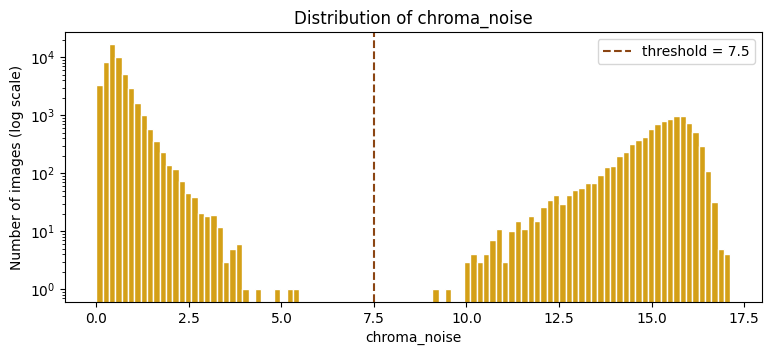

In [27]:
plot_score("chroma_noise", THRESHOLDS["chroma_noise_min"])

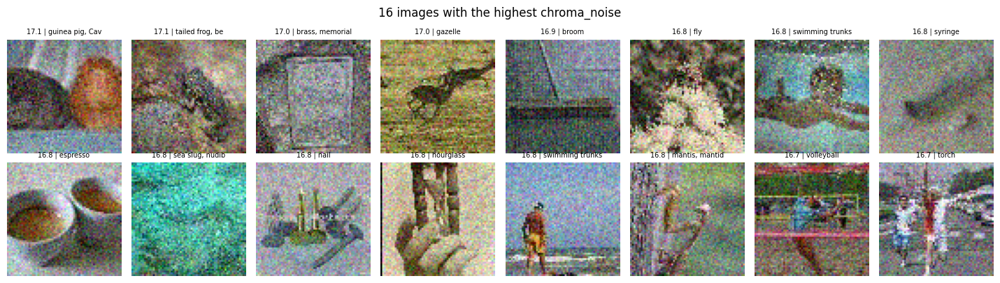

In [28]:
show_extremes("chroma_noise", highest=True)

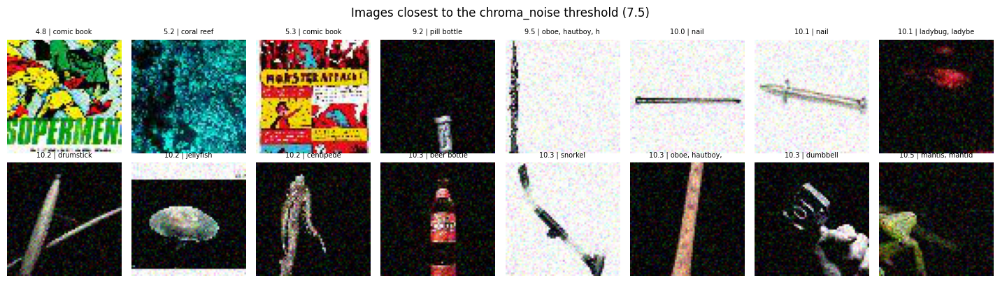

In [29]:
show_around_threshold("chroma_noise", THRESHOLDS["chroma_noise_min"])

**Grain noise in brightness (`luma_noise`).** We also tested the same noise estimate on the brightness channel, as a safety net for noise that is not coloured. The histogram below has a **single mode** and the images with the highest values are textures (thatch, spider webs, coral), not noisy images – so this score does **not** separate noisy from clean images and is **not used** as a criterion.

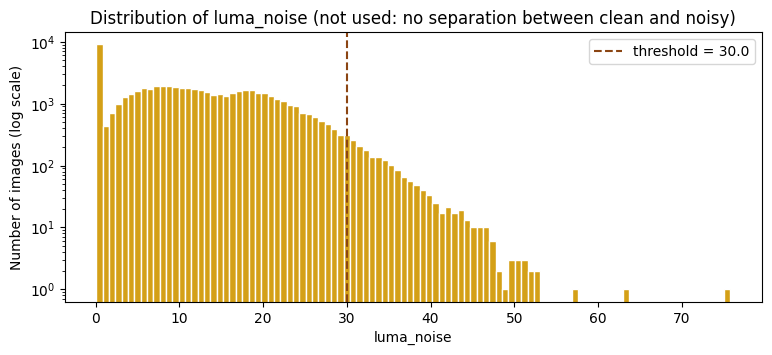

In [30]:
plot_score("luma_noise", 30.0, title="Distribution of luma_noise (not used: no separation between clean and noisy)")

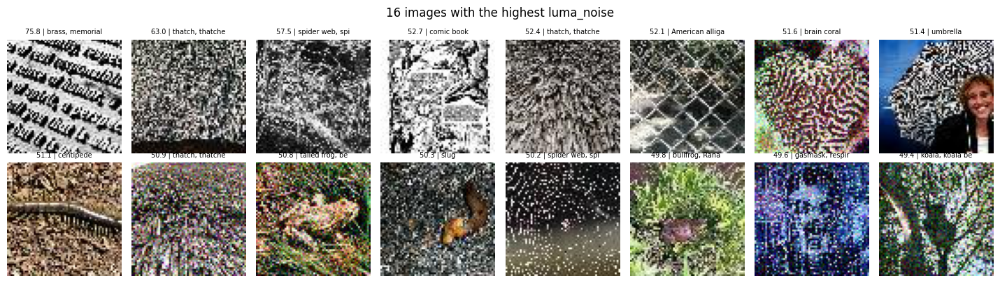

In [31]:
show_extremes("luma_noise", highest=True)

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">6.3. Blur</h4>
</div>

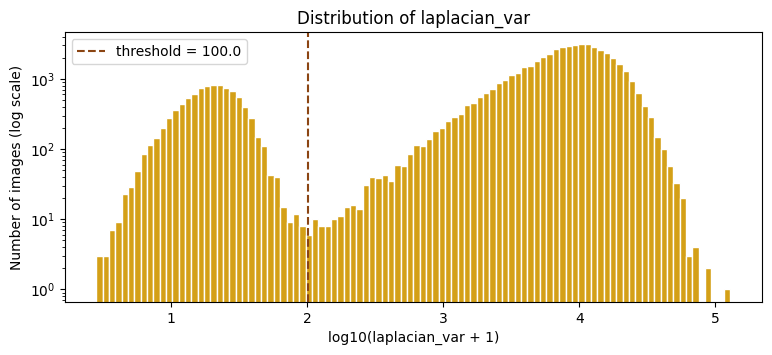

In [32]:
plot_score("laplacian_var", THRESHOLDS["laplacian_var_max"], log=True)

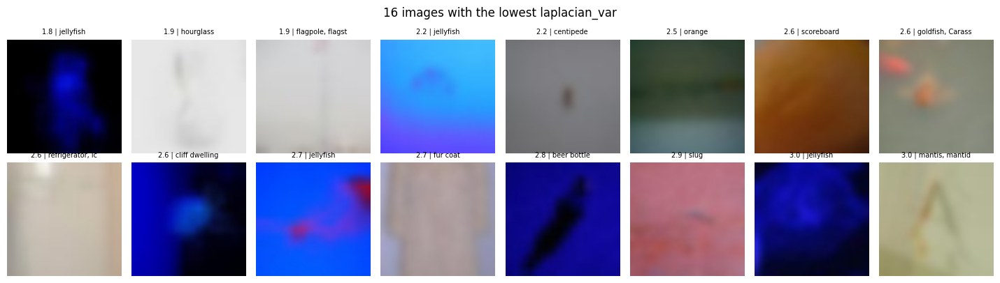

In [33]:
show_extremes("laplacian_var", highest=False)

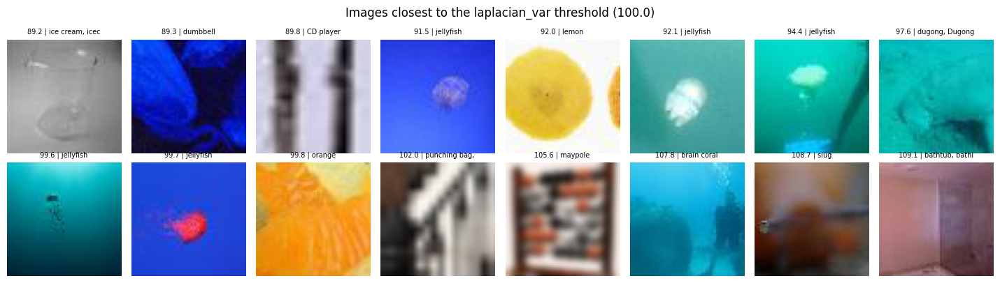

In [34]:
show_around_threshold("laplacian_var", THRESHOLDS["laplacian_var_max"])

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">6.4. Grayscale-Looking RGB Images</h4>
</div>

Images stored as RGB whose three channels are (almost) identical. They look grayscale but were not detected in Section 4 because their mode is `RGB`.

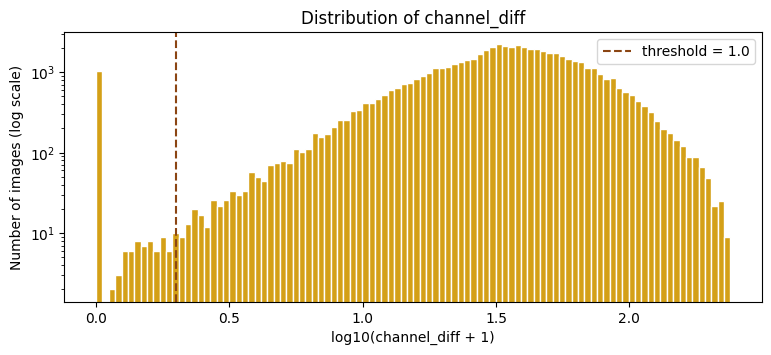

In [35]:
plot_score("channel_diff", THRESHOLDS["channel_diff_max"], log=True)

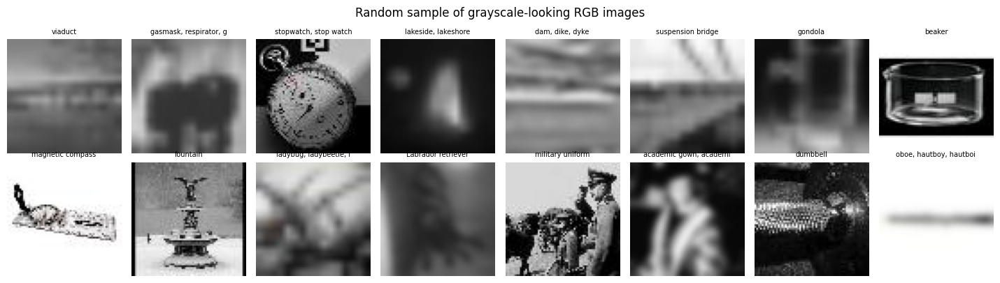

In [36]:
sample = df[df["is_gray_rgb"]].sample(min(16, df["is_gray_rgb"].sum()), random_state=SEED)
show_grid(sample["filename"], sample["description"], suptitle="Random sample of grayscale-looking RGB images")

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">6.5. Borders / Frames</h4>
</div>

In [37]:
print(df["frame_sides"].value_counts().sort_index())

frame_sides
0    56196
1     2947
2      778
3       55
4       24
Name: count, dtype: int64


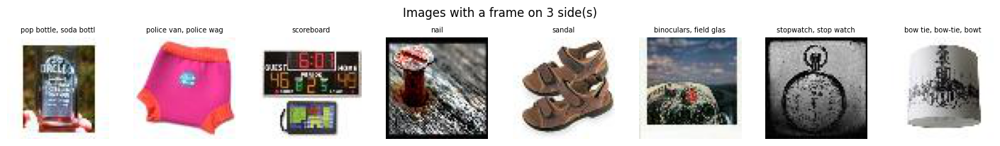

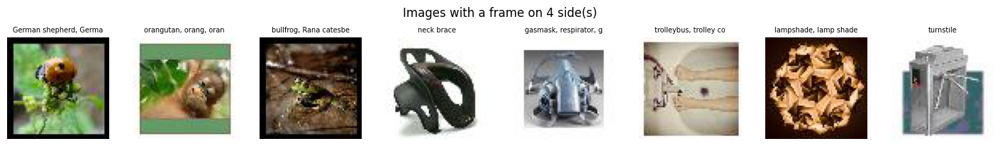

In [38]:
for n_sides in sorted(df.loc[df["has_frame"], "frame_sides"].unique()):
    sample = df[df["frame_sides"] == n_sides]
    sample = sample.sample(min(8, len(sample)), random_state=SEED)
    show_grid(sample["filename"], sample["description"], suptitle=f"Images with a frame on {n_sides} side(s)")

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">6.6. Near-Constant Images</h4>
</div>

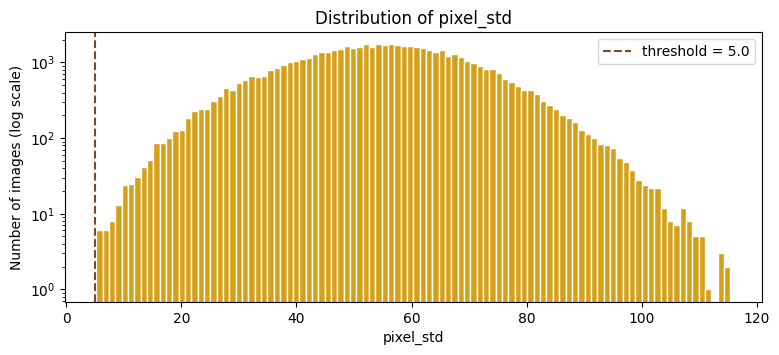

In [39]:
plot_score("pixel_std", THRESHOLDS["pixel_std_max"])

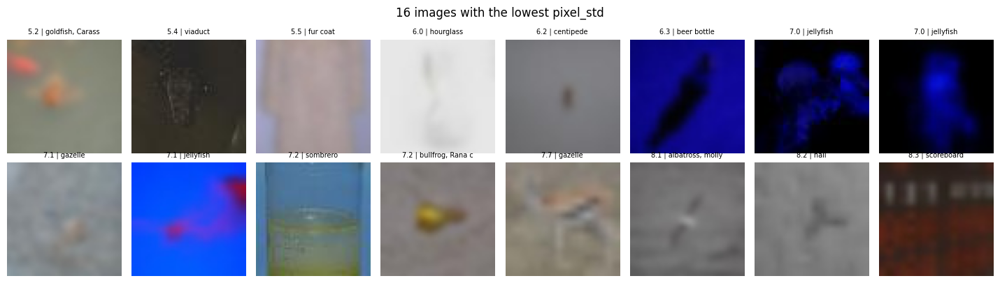

In [40]:
show_extremes("pixel_std", highest=False)

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">6.7. Exposure, Contrast and Colour Cast</h4>
</div>

Noise and blur are not the only possible alterations: an image can also be **too dark, too bright, low-contrast or dominated by one colour** (a colour cast). A model-based audit by the group tagged a category of "other" corruptions with a high error rate, so we check these properties explicitly.

**Detect:** three simple scores per image –
- `brightness`: mean gray level (0 = black, 255 = white), already computed in Section 5;
- `pixel_std`: standard deviation of the gray levels = **contrast**, already computed;
- `colour_cast`: difference between the strongest and the weakest mean channel (R, G, B); high = one colour dominates.

Outliers are flagged with the **IQR rule from Class 3**: a value is an outlier when it lies below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. Following the same class, a flagged image is **investigated before any decision** – an outlier is not removed automatically.

In [ ]:
# Mean of each colour channel per image (one pass over the images, ~20 s)
channel_means = []
for fname in tqdm(df["filename"], desc="Channel means"):
    with Image.open(os.path.join(IMG_DIR, fname)) as im:
        channel_means.append(np.asarray(im.convert("RGB"), dtype=np.float32).reshape(-1, 3).mean(axis=0))
channel_means = np.array(channel_means)
df["mean_r"], df["mean_g"], df["mean_b"] = channel_means.T
df["colour_cast"] = channel_means.max(axis=1) - channel_means.min(axis=1)


def iqr_bounds(values):
    """Class 3 rule: outliers lie below Q1 - 1.5*IQR or above Q3 + 1.5*IQR."""
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


for col in ["brightness", "pixel_std", "colour_cast"]:
    low, high = iqr_bounds(df[col])
    df[f"{col}_outlier"] = (df[col] < low) | (df[col] > high)
    print(f"{col:12s} bounds [{low:6.1f}, {high:6.1f}] -> "
          f"{(df[col] < low).sum():5d} below, {(df[col] > high).sum():5d} above")

df["is_exposure_outlier"] = df[["brightness_outlier", "pixel_std_outlier", "colour_cast_outlier"]].any(axis=1)
print(f"\nImages with at least one exposure / contrast / colour outlier: {df['is_exposure_outlier'].sum()} "
      f"({df['is_exposure_outlier'].mean():.1%})")

In [ ]:
# Distributions with the IQR bounds
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, col in zip(axes, ["brightness", "pixel_std", "colour_cast"]):
    low, high = iqr_bounds(df[col])
    ax.hist(df[col], bins=80, color=GOLD, edgecolor="white")
    for b in (low, high):
        ax.axvline(b, color=BROWN, linestyle="--")
    ax.set_yscale("log")
    ax.set_title(f"{col} (dashed = IQR bounds)")
    ax.set_xlabel(col)
axes[0].set_ylabel("Number of images (log scale)")
plt.tight_layout()
plt.show()

In [ ]:
# Investigate: the most extreme images of each score
show_extremes("brightness", highest=False)    # darkest
show_extremes("brightness", highest=True)     # brightest
show_extremes("pixel_std", highest=True)      # highest contrast
show_extremes("colour_cast", highest=True)    # strongest colour cast

In [ ]:
# Are the outliers a separate corruption, or the noisy / blurred images again?
outliers = df[df["is_exposure_outlier"]]
print(f"Outliers that are also noisy:  {outliers['is_noisy'].mean():.1%}  (all images: {df['is_noisy'].mean():.1%})")
print(f"Outliers that are also blurry: {outliers['is_blurry'].mean():.1%}  (all images: {df['is_blurry'].mean():.1%})")

# Random sample of outliers that are neither noisy nor blurry: what do they look like?
other = outliers[~(outliers["is_noisy"] | outliers["is_blurry"])]
sample = other.sample(min(16, len(other)), random_state=SEED)
titles = [f"b{b:.0f} c{c:.0f} | {d}" for b, c, d in zip(sample["brightness"], sample["colour_cast"], sample["description"])]
show_grid(sample["filename"], titles, suptitle="Outliers that are neither noisy nor blurry (b = brightness, c = colour cast)")

<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Key observations:</h4>


*Fill in after running the cells above – keep the sentence in each pair that matches what you see.*

<font color='#B8860B'>Detect</font>

- IQR rule: [N] brightness outliers, [N] contrast outliers and [N] colour-cast outliers – [N] images ([x]%) in total.

<font color='#B8860B'>Investigate</font>

- The histograms [show one smooth distribution with long tails / show a separate group of values, like `chroma_noise`].
- The darkest and brightest images are [natural photos – night scenes, snow, studio shots on white / images whose brightness was shifted artificially].
- The strongest colour casts are [natural – underwater scenes, sunsets, jellyfish on blue / artificial – the same tint over the whole image].
- [x]% of the outliers are also noisy or blurred, against 30% in the whole dataset.

<font color='#B8860B'>Decide</font>

- **If the outliers are natural photos:** keep them. The IQR rule flags the tails of any distribution; extreme lighting and colours are part of real photos, and colour is informative for classes such as *lemon* or *jellyfish*.
- **If they form a separate, artificial group:** keep them and treat them like noise and blur – add the flag to the `degradation` column, stratify the split on it and report results on this subset in Part IV.


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">6.8. Overlap and Distribution Across Classes</h4>
</div>

Do the issues occur together (e.g. blurred images that are also grayscale)? And are they spread evenly across classes and size tiers, or concentrated in some of them? A concentration would mean the corruption was applied to specific classes, which would bias the model.

In [41]:
# Co-occurrence of the flags: cell (i, j) = number of images with both flag i and flag j
co = df[FLAGS].astype(int).T @ df[FLAGS].astype(int)
co

,is_noisy,is_blurry,is_gray_mode,is_gray_rgb,has_frame,is_blank
is_noisy,9000,0,0,0,0,0
is_blurry,0,9041,0,178,7,0
is_gray_mode,0,0,806,0,2,0
is_gray_rgb,0,178,0,279,1,0
has_frame,0,7,2,1,79,0
is_blank,0,0,0,0,0,0


In [42]:
# Share of degraded images per size tier
df["is_degraded"] = df["is_noisy"] | df["is_blurry"]
df.groupby("size_tier", observed=True)[["is_noisy", "is_blurry", "has_frame", "is_gray_rgb"]].mean().round(3)

,is_noisy,is_blurry,has_frame,is_gray_rgb
size_tier,,,,
small,0.153,0.155,0.001,0.005
medium-low,0.150,0.147,0.001,0.004
medium-high,0.151,0.149,0.001,0.004
large,0.149,0.153,0.001,0.005


count    200.000
mean       0.301
std        0.031
min        0.228
25%        0.280
50%        0.302
75%        0.320
max        0.445
Name: is_degraded, dtype: float64 

description
barrel, cask                                                                                       0.445
steel arch bridge                                                                                  0.385
trilobite                                                                                          0.384
mushroom                                                                                           0.380
bighorn, bighorn sheep, cimarron, Rocky Mountain bighorn, Rocky Mountain sheep, Ovis canadensis    0.366
bell pepper                                                                                        0.364
golden retriever                                                                                   0.363
banana                                                                           

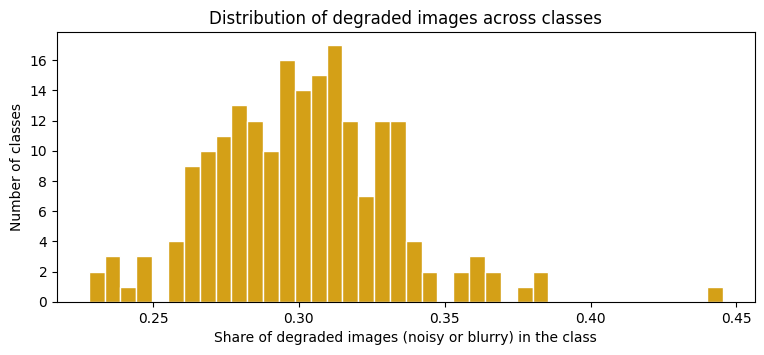

In [43]:
# Classes with the highest share of degraded images
degraded_share = df.groupby("description")["is_degraded"].mean().sort_values(ascending=False)
print(degraded_share.describe().round(3), "\n")
print(degraded_share.head(10).round(3))

plt.figure(figsize=(9, 3.5))
plt.hist(degraded_share, bins=40, color=GOLD, edgecolor="white")
plt.xlabel("Share of degraded images (noisy or blurry) in the class")
plt.ylabel("Number of classes")
plt.title("Distribution of degraded images across classes")
plt.show()

<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Key observations:</h4>


<font color='#B8860B'>Detect</font>

| Issue | Score and threshold | Images flagged |
|---|---|---|
| Heavy colour noise | `chroma_noise` > 7.5 | 9,000 (15.0%) |
| Strong blur | `laplacian_var` < 100 | 9,041 (15.1%) |
| Grayscale-looking RGB | `channel_diff` < 1 | 279 |
| Frames | `frame_sides` ≥ 3 | 79 |
| Near-constant images | `pixel_std` < 5 | 0 |
| Grain noise | `luma_noise` | not used (see below) |
| Exposure / contrast / colour cast | IQR rule on `brightness`, `pixel_std`, `colour_cast` | see Section 6.7 |

<font color='#B8860B'>Investigate</font>

- **Colour noise:** `chroma_noise` is clearly **bimodal** – clean images between 0 and 5, noisy images between 9 and 17.5, with an empty gap. The threshold of 7.5 sits in the middle of the gap, because the images just above 5 (e.g. *coral reef*, *comic book*) are clean but very colourful. **Exactly 15.0%** of the images are noisy, which strongly suggests the noise was **injected artificially** into a fixed fraction of the dataset. In most noisy images the object is still recognisable.
- **Grain noise (`luma_noise`):** unimodal distribution; the highest values are **textures** (thatch, spider webs, coral), not noise, so the score is discarded.
- **Blur:** `laplacian_var` is **bimodal** on a log scale, with a valley around 100. Again almost exactly 15% – most likely 9,000 artificially blurred images plus a few naturally blurry photos. The lowest values are colour blobs where the object is barely visible.
- **Noise and blur never occur together** (co-occurrence = 0): each image received **at most one** corruption.
- **Grayscale-looking RGB:** 178 of the 279 are also blurry; the rest are genuine black-and-white photos (e.g. *stopwatch*, *military uniform*).
- **Frames:** a uniform strip on 1–2 sides is usually a natural background (sky, wall), so only 3–4 framed sides are flagged (e.g. the black frame around *German shepherd*). The object is fully visible.
- **Near-constant images:** none – the lowest `pixel_std` values are blurred images, not blank ones.
- **Distribution:** noisy and blurred images make up about **15% each in every size tier**, and the share per class varies only moderately around the mean. The corruption was applied **uniformly at random**, not to specific classes.

<font color='#B8860B'>Decide</font>

- **Noisy and blurred images are kept** (~30% of the data). Removing them would discard a large part of the data, the objects are often still recognisable, and testing only on clean images would overestimate real-world performance. The split is stratified by class **and** degradation type, and in Part III we run a **sensitivity analysis**: training with vs. without the degraded images, evaluated separately on the clean, noisy and blurry test subsets.
- **Grayscale images** (mode `L` and grayscale-looking RGB): kept and converted to 3 channels.
- **Frames:** kept, and the flag is used in the error analysis.


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">7. Visual Inspection</h3>
</div>

Before deciding on label noise, we look at random images of a few classes. This shows what a 'normal' image looks like at 64×64 and reveals images that clearly do not belong to their class.

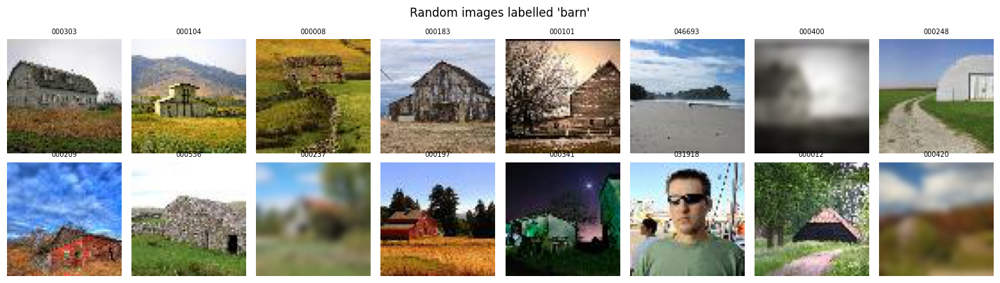

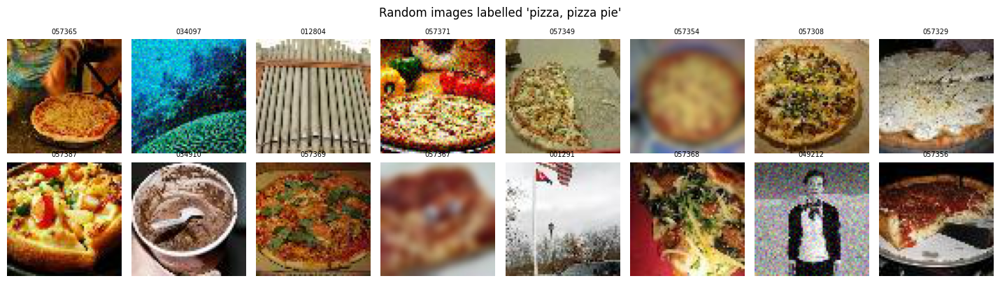

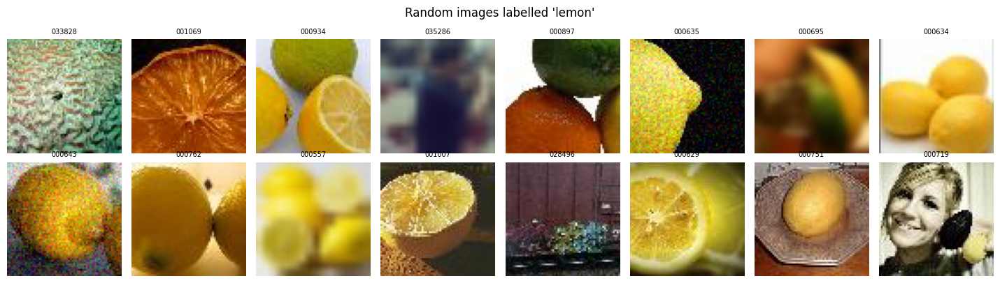

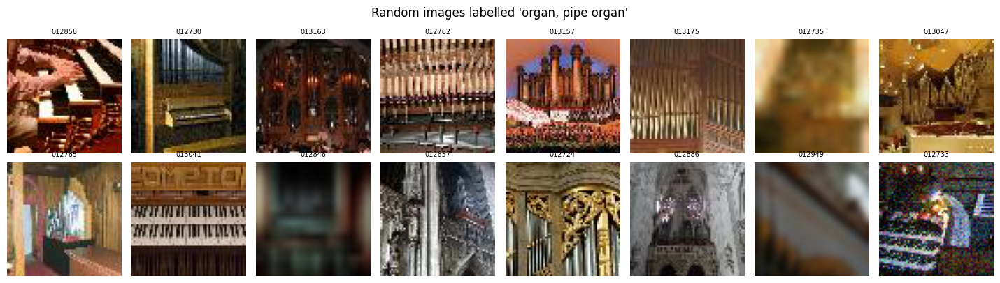

In [44]:
example_classes = ["barn", "pizza, pizza pie", "lemon", "organ, pipe organ"]
for cls in example_classes:
    sample = df[df["description"] == cls].sample(16, random_state=SEED)
    show_grid(sample["filename"], [f"{f[6:12]}" for f in sample["filename"]], suptitle=f"Random images labelled '{cls}'")

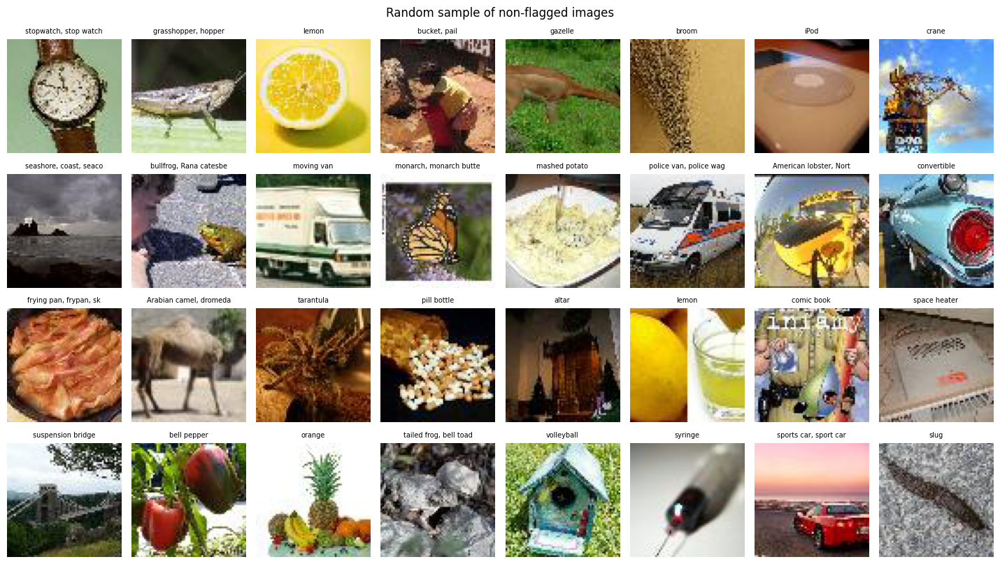

In [45]:
# Random sample of the whole dataset after excluding the flagged images
clean_view = df[~(df["is_degraded"] | df["is_blank"])].sample(32, random_state=SEED)
show_grid(clean_view["filename"], clean_view["description"], suptitle="Random sample of non-flagged images")

<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Key observations:</h4>


- Even at 64×64, most objects in the non-flagged images are recognisable, but small objects in large scenes are hard to distinguish, so some confusion between visually similar classes is expected.
- Some images clearly do not match their label – e.g. `image_000001.JPEG`, labelled *cliff dwelling* but showing a barn, and an image labelled *sandal* that shows a jellyfish (Section 5.2). This confirms the presence of **label noise** beyond the duplicates with conflicting labels.


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">8. Label Noise</h3>
</div>

We follow the rule from Class 3 for outliers, applied here to data-quality issues: an observation is not removed only because a method flags it. Each issue is handled in three steps: **Detect** (a method that flags it), **Investigate** (look at the flagged cases) and **Decide** (keep, correct or remove, with a justification).

Evidence of label noise so far:
1. **Duplicates with conflicting labels** (Section 5) – the same image cannot belong to two classes.
2. **Images that visually do not match their label** (Sections 1, 5 and 7, e.g. `image_000001.JPEG`).

Visual inspection cannot cover 60,000 images. Section 8.2 uses a simple, label-free property of the dataset – **the order of the files** – to detect suspicious labels at scale.

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">8.1. Duplicates with Conflicting Labels</h4>
</div>

In [46]:
n_conflict_exact = df["md5"].isin(exact_conflicting).sum()
n_conflict_near = df["dup_group"].isin(near_conflicting).sum()
print(f"Images in exact-duplicate groups with conflicting labels: {n_conflict_exact}")
print(f"Images in near-duplicate groups with conflicting labels: {n_conflict_near}")

# Which classes are involved in the conflicts? (pairs of labels given to the same image)
conflicts = df[df["md5"].isin(exact_conflicting)]
pairs = (conflicts.groupby("md5")["description"]
                  .apply(lambda s: " | ".join(sorted(s.unique())))
                  .value_counts())
pairs.head(15)

Images in exact-duplicate groups with conflicting labels: 12
Images in near-duplicate groups with conflicting labels: 36


description
iPod | sock                                                                                                                                         1
banana | lemon                                                                                                                                      1
American lobster, Northern lobster, Maine lobster, Homarus americanus | spiny lobster, langouste, rock lobster, crawfish, crayfish, sea crawfish    1
CD player | fur coat                                                                                                                                1
sea slug, nudibranch | slug                                                                                                                         1
orange | parking meter                                                                                                                              1
Name: count, dtype: int64

If the conflicting pairs are mostly **random combinations of unrelated classes** (e.g. *barn | lemon*), the noise was injected artificially at random. If they are pairs of **similar classes**, the noise comes from genuine ambiguity.

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">
<h4 style="color:#D4A017;">8.2. Label Noise Revealed by the File Order</h4>
</div>

The files are numbered (`image_000001` to `image_060000`) and, when sorted by number, images of the same class appear in **long consecutive blocks** (e.g. `image_000002` to `image_000029` are all *barn*). Inside these blocks, single images sometimes carry a **different label** – for example `image_000030` is labelled *magnetic compass* between two *barn* images.

**Detect:** an image is flagged as a **suspect label** when its two neighbours in the file order share the same class and its own label is different ("sandwiched" label). This method does not use any model or image content, so it is independent of the other checks.

This is a **conservative** detector (a lower bound): it misses wrong labels at the boundary between two blocks and two consecutive wrong labels.

In [47]:
# Sort the images by file number and compare each label with its two neighbours
file_no = df["filename"].str.extract(r"(\d+)", expand=False).astype(int)
order = df.assign(file_no=file_no).sort_values("file_no")
prev_cls, next_cls = order["class_id"].shift(1), order["class_id"].shift(-1)

order["neighbour_class"] = prev_cls.where(prev_cls == next_cls)      # defined only when both neighbours agree
order["suspect_label"] = order["neighbour_class"].notna() & (order["class_id"] != order["neighbour_class"])
isolated = (order["class_id"] != prev_cls) & (order["class_id"] != next_cls)

df["file_no"] = df["filename"].map(order.set_index("filename")["file_no"])
df["neighbour_class"] = df["filename"].map(order.set_index("filename")["neighbour_class"])
df["suspect_label"] = df["filename"].map(order.set_index("filename")["suspect_label"]).astype(bool)

# Block structure once the suspect labels are ignored
block_cls = order["class_id"].where(~order["suspect_label"]).ffill()
blocks = block_cls.groupby((block_cls != block_cls.shift()).cumsum()).first()

print(f"Suspect labels (label differs from both neighbours, which agree): {df['suspect_label'].sum()} "
      f"({df['suspect_label'].mean():.1%})")
print(f"Isolated labels at block boundaries (neighbours disagree, not flagged): {(isolated & ~order['suspect_label']).sum()}")
print(f"Blocks after ignoring suspect labels: {len(blocks)} | blocks per class: "
      f"min {blocks.value_counts().min()}, median {blocks.value_counts().median():.0f}, max {blocks.value_counts().max()}")

Suspect labels (label differs from both neighbours, which agree): 4846 (8.1%)
Isolated labels at block boundaries (neighbours disagree, not flagged): 1718
Blocks after ignoring suspect labels: 1870 | blocks per class: min 2, median 9, max 17


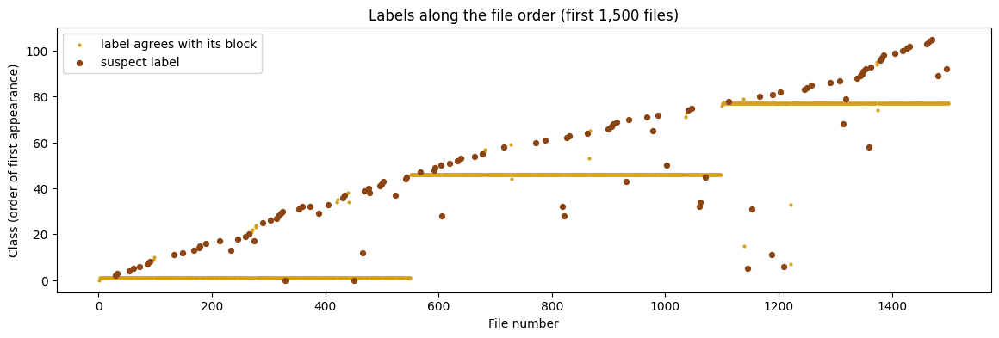

In [48]:
# Visual check of the block structure: class of each image along the file order
first = order.head(1500)
class_code = pd.Series(pd.factorize(first["class_id"])[0], index=first.index)
sus = first["suspect_label"]

plt.figure(figsize=(14, 4))
plt.scatter(first.loc[~sus, "file_no"], class_code[~sus], s=4, color=GOLD, label="label agrees with its block")
plt.scatter(first.loc[sus, "file_no"], class_code[sus], s=18, color=BROWN, label="suspect label")
plt.xlabel("File number")
plt.ylabel("Class (order of first appearance)")
plt.title("Labels along the file order (first 1,500 files)")
plt.legend()
plt.show()

size_tier
small          0.205
medium-low     0.113
medium-high    0.070
large          0.046
Name: suspect_label, dtype: float64


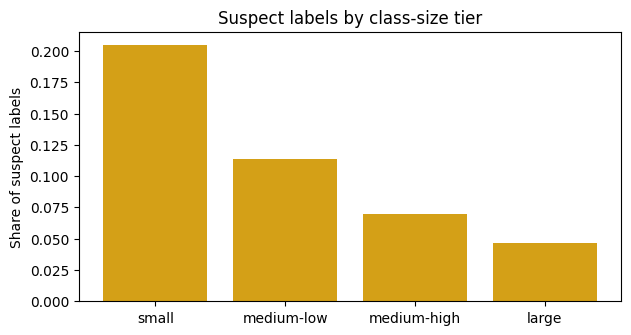

In [49]:
# Is the suspect-label rate the same for every class size?
rate = df.groupby("size_tier", observed=True)["suspect_label"].mean()
print(rate.round(3))

plt.figure(figsize=(7, 3.5))
plt.bar(rate.index.astype(str), rate.values, color=GOLD)
plt.ylabel("Share of suspect labels")
plt.title("Suspect labels by class-size tier")
plt.show()

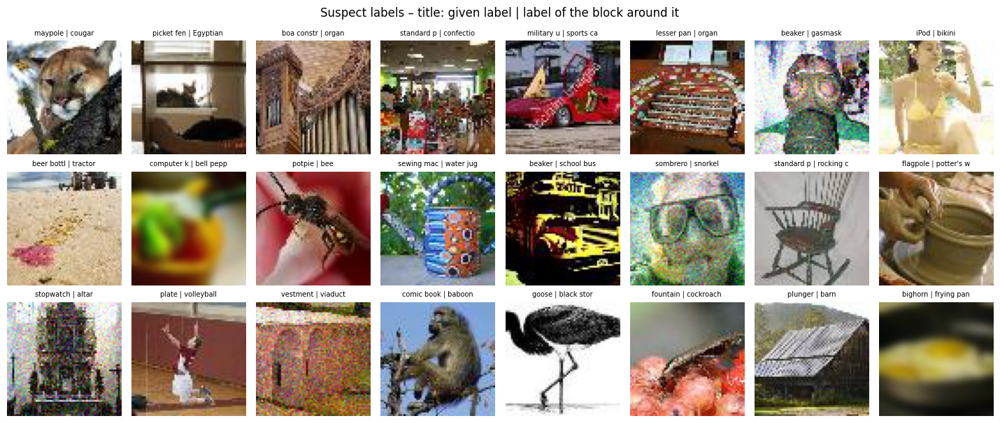

In [50]:
# Investigate: given label vs. the class of the block around it
id_to_desc = labels.drop_duplicates("class_id").set_index("class_id")["description"].str.split(",").str[0]
suspects = df[df["suspect_label"]]
sample = suspects.sample(min(24, len(suspects)), random_state=SEED)
titles = [f"{id_to_desc[g][:10]} | {id_to_desc[n][:10]}" for g, n in zip(sample["class_id"], sample["neighbour_class"])]
show_grid(sample["filename"], titles, suptitle="Suspect labels – title: given label | label of the block around it")

In [51]:
# Is the label noise related to the image corruptions?
print(pd.crosstab(np.select([df["is_noisy"], df["is_blurry"]], ["noisy", "blurry"], "clean"),
                  df["suspect_label"], normalize="index", rownames=["degradation"], colnames=["label"]).round(3).rename(columns={False: "ok", True: "suspect"}))

# Conflicting duplicates (Section 5): which copy is the suspect one?
pairs_check = (df[df["md5"].isin(exact_conflicting)]
               .assign(description=lambda d: d["description"].str.split(",").str[0])
               [["md5", "filename", "description", "suspect_label"]].sort_values("md5"))
pairs_check

label           ok  suspect
degradation                
blurry       0.917    0.083
clean        0.920    0.080
noisy        0.919    0.081


,md5,filename,description,suspect_label
15109,0f90581135f442e3ccdd383b63e46ee2,image_015110.JPEG,iPod,False
48341,0f90581135f442e3ccdd383b63e46ee2,image_048342.JPEG,sock,False
1090,14d8d0a7ddc80a806c16844d80c06d1c,image_001091.JPEG,lemon,False
59133,14d8d0a7ddc80a806c16844d80c06d1c,image_059134.JPEG,banana,False
33613,a0be107a9cac5fd94a8edcc17e7ed810,image_033614.JPEG,spiny lobster,False
40382,a0be107a9cac5fd94a8edcc17e7ed810,image_040383.JPEG,American lobster,False
27766,b9949ad1aa236513281dfc352211b7a7,image_027767.JPEG,fur coat,False
47291,b9949ad1aa236513281dfc352211b7a7,image_047292.JPEG,CD player,True
11907,d5f94f137e28023f7e6c6c799b100a92,image_011908.JPEG,sea slug,False
30312,d5f94f137e28023f7e6c6c799b100a92,image_030313.JPEG,slug,False


<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Key observations:</h4>


<font color='#B8860B'>Detect</font>

- **Conflicting duplicates:** 12 images (6 pairs).
- **File order:** **4,846 images (8.1%)** have a label that differs from both of their neighbours, which share the same class. Sorted by file number, every class appears in several long blocks (about 9 blocks per class).

<font color='#B8860B'>Investigate</font>

- The grid of suspect labels shows that, in most cases, the image matches the class of the **block around it**, not its given label – so the given label is the wrong one.
- The share of suspect labels **falls with class size**: **20.5%** in the smallest classes, 11.3% and 7.0% in the middle tiers and **4.6%** in the largest. The wrong labels are concentrated in the small classes, so the small classes are both smaller **and** noisier.
- Half of the conflicting-duplicate pairs are unrelated classes (*iPod / sock*, *fur coat / CD player*, *parking meter / orange*) and the other half similar classes or two objects in one image. Together with the file-order pattern, this points to **artificially injected** label noise.
- The crosstab shows whether the suspect labels are spread evenly over clean, noisy and blurry images, i.e. whether label noise and image corruption were injected independently.
- The detector is a **lower bound**: wrong labels at block boundaries and consecutive wrong labels are not flagged, so the real noise rate is probably higher than 8%.

<font color='#B8860B'>Decide</font>

- **Conflicting duplicates:** removed (Section 10).
- **Suspect labels: kept and flagged** (`suspect_label`), not removed automatically. Following Class 3, we run a **sensitivity analysis** in Part III: the same model trained on all labels vs. without the suspect training rows. Validation and test keep the given labels, and we also report accuracy on the **unflagged** validation rows, where errors are less likely to be caused by wrong labels.
- **Label smoothing** is tested during training, since it reduces the impact of wrong labels.
- Because the noise is concentrated in the small classes, removing the suspect rows would make the class imbalance **worse** – another reason to test this decision instead of applying it blindly.


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">9. Summary of Findings and Decisions</h3>
</div>

The table below is computed from the data, so its numbers always match the current thresholds.

In [52]:
summary = pd.DataFrame([
    ["Corrupted / unreadable files", "Full decoding with PIL", int((~df["readable"]).sum()), "None found"],
    ["Wrong image size", "PIL width/height", int(((df["width"] != 64) | (df["height"] != 64)).sum()), "None found"],
    ["Grayscale-mode images (L)", "PIL mode", int(df["is_gray_mode"].sum()), "Keep, convert to RGB"],
    ["Grayscale-looking RGB images", "channel_diff", int(df["is_gray_rgb"].sum()), "Keep"],
        ["Exact duplicates – conflicting labels", "MD5 + class_id", int(n_conflict_exact), "Remove all copies"],
    ["dHash near-duplicate groups", "dHash + pixel difference", int(len(near_only)), "False positives – not treated as duplicates"],
    ["Heavy colour noise", "chroma_noise", int(df["is_noisy"].sum()), "Keep; stratify split; evaluate separately"],
    ["Strong blur", "laplacian_var", int(df["is_blurry"].sum()), "Keep; stratify split; evaluate separately"],
    ["Borders / frames", "frame_sides", int(df["has_frame"].sum()), "Keep, flag for error analysis"],
    ["Near-constant images", "pixel_std", int(df["is_blank"].sum()), "None found"],
    ["Exposure / contrast / colour-cast outliers", "IQR rule (Class 3)", int(df["is_exposure_outlier"].sum()), "Investigated in 6.7 – see decision there"],
    ["Class imbalance (ratio 5.08, 4 tiers)", "value_counts", 200, "Stratified split, class weights, macro-F1"],
    ["Grain noise (luma)", "luma_noise", None, "Score discarded – does not separate"],
    ["Suspect labels (file order)", "label differs from both neighbours", int(df["suspect_label"].sum()), "Keep, flag; sensitivity analysis in Part III"],
    ["Visual label noise", "Visual inspection", None, "Label smoothing"],
], columns=["Issue", "Detection method", "# cases", "Decision"])
summary

,Issue,Detection method,# cases,Decision
0,Corrupted / unreadable files,Full decoding with PIL,0.0,None found
1,Wrong image size,PIL width/height,0.0,None found
2,Grayscale-mode images (L),PIL mode,806.0,"Keep, convert to RGB"
3,Grayscale-looking RGB images,channel_diff,279.0,Keep
4,Exact duplicates – conflicting labels,MD5 + class_id,12.0,Remove all copies
5,dHash near-duplicate groups,dHash + pixel difference,38.0,False positives – not treated as duplicates
6,Heavy colour noise,chroma_noise,9000.0,Keep; stratify split; evaluate separately
7,Strong blur,laplacian_var,9041.0,Keep; stratify split; evaluate separately
8,Borders / frames,frame_sides,79.0,"Keep, flag for error analysis"
9,Near-constant images,pixel_std,0.0,None found


<div style="background-color:#FAF7F2; color:#2B2B2B; padding:15px; border-radius:10px;">

| Decision | Justification |
|---|---|
| Convert grayscale to RGB | Models expect 3 channels; the images are valid and grayscale photos can also appear at test time. |
| Remove conflicting duplicates | The correct label is unknown; keeping them adds wrong labels to training or to the ground truth. Removing them before splitting also prevents **data leakage**. |
| Do not use dHash groups | Images inside a group are different photographs (mean pixel difference 74.9/255). |
| Keep noisy and blurred images | ~30% of the data, objects often still recognisable; removing them would shrink the data and make the test unrealistically easy. Effect tested in Part III. |
| Stratify by class and degradation | Every partition has the same share of clean, noisy and blurry images, so results are comparable. |
| Keep framed images | Object fully visible; frames are a small realistic variation. |
| Stratified split + class weights + macro-F1 | Imbalance ratio of 5: every class must be represented and weighted fairly. |
| Keep and flag suspect labels | 8.1% of the labels are suspect and they are concentrated in the small classes; removing them blindly would worsen the imbalance, so removal is tested in Part III. |
| Label smoothing | The remaining label noise cannot be removed by hand; label smoothing reduces its impact. |

</div>

In [53]:
# Save the per-image statistics (all checks and scores) for reproducibility
df.to_csv(os.path.join(OUTPUT_DIR, "image_stats.csv"), index=False)
print(f"Saved {len(df)} rows to {OUTPUT_DIR}/image_stats.csv")

Saved 60000 rows to outputs/image_stats.csv


<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h2 style="color:#2B2B2B;"><b>PART II – Preprocessing</b></h2>
</div>

In this part we turn the decisions of Part I into a clean, reproducible dataset:
1. apply the data-quality decisions (Section 10);
2. encode the labels as integers (Section 11);
3. create stratified train / validation / test partitions (Section 12);
4. compute class weights (Section 13);
5. build an efficient `tf.data` input pipeline and the data augmentation (Sections 14–15).

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">10. Applying the Data-Quality Decisions</h3>
</div>

Every image receives **at most one exclusion reason**, applied in order of severity. Images without a reason form the dataset used for modelling. Following Part I, only **unreadable**, **near-constant** and **conflicting duplicate** images are removed; noisy and blurred images are **kept** and labelled with their degradation type.

In [54]:
USE_NEAR_DUPLICATES = False  # dHash groups are false positives (Section 5.2): only exact duplicates are used

data = df.copy()
data["exclude_reason"] = None

def set_reason(mask, reason):
    """Assign an exclusion reason only to images that do not have one yet."""
    data.loc[mask & data["exclude_reason"].isna(), "exclude_reason"] = reason

# 1) Unreadable images and near-constant images
set_reason(~data["readable"], "unreadable")
set_reason(data["is_blank"], "near_constant")

# 2) Duplicates: the grouping key is the dHash (exact duplicates always share it) or the MD5 only
data["dup_key"] = data["dup_group"].fillna(data["md5"]) if USE_NEAR_DUPLICATES else data["md5"]
group_n_labels = data.groupby("dup_key")["class_id"].transform("nunique")
group_size = data.groupby("dup_key")["filename"].transform("count")

set_reason((group_size > 1) & (group_n_labels > 1), "duplicate_conflicting_labels")
is_extra_copy = data.duplicated("dup_key", keep="first") & (group_n_labels == 1)
set_reason(is_extra_copy, "duplicate_copy")


print(data["exclude_reason"].fillna("kept").value_counts())

exclude_reason
kept                            59988
duplicate_conflicting_labels       12
Name: count, dtype: int64


In [55]:
clean = data[data["exclude_reason"].isna()].copy()
clean["degradation"] = np.select([clean["is_noisy"], clean["is_blurry"]], ["noisy", "blurry"], "clean")

print(f"Original images:  {len(data)}")
print(f"Kept for modelling: {len(clean)} ({len(clean) / len(data):.1%})")
print(f"Removed:          {len(data) - len(clean)}\n")
print(clean["degradation"].value_counts())

# The class distribution must not change much after cleaning
after = clean["description"].value_counts()
lost = (1 - after / class_counts).sort_values(ascending=False)
print(f"\nClasses after cleaning: {after.size}")
print(f"Smallest class after cleaning: {after.min()} images ({after.idxmin()})")
print(f"Largest share of images removed from one class: {lost.max():.1%} ({lost.idxmax()})")

Original images:  60000
Kept for modelling: 59988 (100.0%)
Removed:          12

degradation
clean     41947
blurry     9041
noisy      9000
Name: count, dtype: int64

Classes after cleaning: 200
Smallest class after cleaning: 107 images (banana)
Largest share of images removed from one class: 0.9% (banana)


<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">11. Label Encoding</h3>
</div>

Neural networks need integer labels. We map each `class_id` to an integer from 0 to 199, sorted alphabetically by `class_id` so the mapping is deterministic, and save it so that predictions can be translated back to class names.

In [56]:
class_mapping = (labels[["class_id", "description"]].drop_duplicates()
                 .sort_values("class_id").reset_index(drop=True))
class_mapping["label_idx"] = class_mapping.index
NUM_CLASSES = len(class_mapping)

id_to_idx = dict(zip(class_mapping["class_id"], class_mapping["label_idx"]))
clean["label_idx"] = clean["class_id"].map(id_to_idx)

class_mapping.to_csv(os.path.join(OUTPUT_DIR, "class_mapping.csv"), index=False)
print(f"Number of classes: {NUM_CLASSES}")
class_mapping.head()

Number of classes: 200


,class_id,description,label_idx
0,n01443537,"goldfish, Carassius auratus",0
1,n01629819,"European fire salamander, Salamandra salamandra",1
2,n01641577,"bullfrog, Rana catesbeiana",2
3,n01644900,"tailed frog, bell toad, ribbed toad, tailed to...",3
4,n01698640,"American alligator, Alligator mississipiensis",4


<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">12. Train / Validation / Test Split</h3>
</div>

We follow the split scheme from the course: **20% of the images go to the test set**, and the remaining **80% (train + validation) are split 80/20** into train and validation. Overall this gives **64% train, 16% validation and 20% test**. Both splits are **stratified by class and degradation type** (clean / noisy / blurry). Each partition therefore keeps the class proportions (essential with an imbalance ratio of 5) **and** the same share of degraded images, so the results on each subset are comparable.

```
60,000 images
├── 20% test
└── 80% train + validation
        ├── 80% train       (64% of the total)
        └── 20% validation  (16% of the total)
```

- **Train:** used to fit the model weights.
- **Validation:** used to compare models, tune hyperparameters and for early stopping.
- **Test:** used **only once**, at the end, to evaluate the final model. Using it to choose between models would make the reported result optimistic.

Because duplicates were removed **before** splitting, no image can appear in more than one partition.

In [57]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20   # 20% of all images go to the test set
VAL_FRAC = 0.20    # 20% of train + validation goes to validation (16% of the total)

# Stratification key: class + degradation type (e.g. "17_noisy")
strat_key = clean["label_idx"].astype(str) + "_" + clean["degradation"]
# Safety net: very small groups (< 10 images) are merged into the clean group of their class
group_size = strat_key.map(strat_key.value_counts())
strat_key = strat_key.where(group_size >= 10, clean["label_idx"].astype(str) + "_clean")
print(f"Stratification groups: {strat_key.nunique()} "
      f"({(group_size < 10).sum()} images in groups too small to use the degradation type)")

train_val, test = train_test_split(clean, test_size=TEST_SIZE,
                                   stratify=strat_key, random_state=SEED)
train, val = train_test_split(train_val, test_size=VAL_FRAC,
                              stratify=strat_key.loc[train_val.index], random_state=SEED)

for name, part_df in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:>5}: {len(part_df):6d} images ({len(part_df) / len(clean):.1%}), "
          f"{part_df['label_idx'].nunique()} classes, "
          f"smallest class = {part_df['label_idx'].value_counts().min()} images")

# Share of each degradation type per partition (should be the same everywhere)
pd.DataFrame({name: p["degradation"].value_counts(normalize=True).round(3)
              for name, p in [("train", train), ("val", val), ("test", test)]})

Stratification groups: 597 (25 images in groups too small to use the degradation type)
train:  38392 images (64.0%), 200 classes, smallest class = 67 images
  val:   9598 images (16.0%), 200 classes, smallest class = 17 images
 test:  11998 images (20.0%), 200 classes, smallest class = 21 images


,train,val,test
degradation,,,
clean,0.699,0.699,0.700
blurry,0.151,0.151,0.151
noisy,0.150,0.150,0.149


In [58]:
# Sanity checks: no overlap between partitions (filenames and image content)
assert not set(train["filename"]) & set(val["filename"])
assert not set(train["filename"]) & set(test["filename"])
assert not set(val["filename"]) & set(test["filename"])
assert not set(train["md5"]) & set(test["md5"]), "Identical images in train and test!"
assert not set(train["md5"]) & set(val["md5"]), "Identical images in train and validation!"
print("No overlap between partitions.")

# Stratification check: class proportions are (almost) the same in every partition
props = pd.DataFrame({name: p["label_idx"].value_counts(normalize=True)
                      for name, p in [("train", train), ("val", val), ("test", test)]})
print(f"Max difference in class proportion between train and test: "
      f"{(props['train'] - props['test']).abs().max():.4f}")

No overlap between partitions.
Max difference in class proportion between train and test: 0.0001


In [59]:
# Save the partitions – later parts of the notebook (and other team members) reuse exactly the same split
KEEP_COLS = ["filename", "class_id", "description", "label_idx", "size_tier",
             "degradation", "suspect_label", "is_gray_mode", "is_gray_rgb", "has_frame"]
splits = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
splits[KEEP_COLS + ["split"]].to_csv(os.path.join(OUTPUT_DIR, "splits.csv"), index=False)
print(pd.crosstab(splits["split"], splits["degradation"], margins=True))

degradation  blurry  clean  noisy    All
split                                   
test           1807   8398   1793  11998
train          5786  26841   5765  38392
val            1448   6708   1442   9598
All            9041  41947   9000  59988


<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">13. Class Weights</h3>
</div>

With **balanced class weights**, the loss of each image is multiplied by `n_samples / (n_classes × n_samples_in_class)`. Errors on small classes therefore cost more, which counteracts the model's tendency to favour large classes. Weights are computed **on the training set only**. Whether they actually help is tested as an experiment in Part III.

In [60]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight(class_weight="balanced",
                               classes=np.arange(NUM_CLASSES),
                               y=train["label_idx"])
CLASS_WEIGHTS = dict(enumerate(weights))

print(f"Min weight: {weights.min():.2f} | Max weight: {weights.max():.2f}")
tier_weights = (train.assign(weight=train["label_idx"].map(CLASS_WEIGHTS))
                     .groupby("size_tier", observed=True)["weight"].mean().round(2))
tier_weights

Min weight: 0.55 | Max weight: 2.87


size_tier
small          2.49
medium-low     1.43
medium-high    0.87
large          0.57
Name: weight, dtype: float64

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">14. Image Input Pipeline</h3>
</div>

All images are **loaded into memory once** as NumPy `uint8` arrays (~0.74 GB) and passed directly to `model.fit`, as in Class 12. Keras shuffles the training data at every epoch, so no `tf.data` pipeline is needed.

- `convert("RGB")` turns grayscale images (`mode = L`) into 3 channels by replicating the channel – this implements the decision of Section 4.
- Loading once is much faster than decoding the JPEG files at every epoch: a first version that decoded the files with `tf.data` and a full-size shuffle buffer took more than 10 minutes before the first batch on a laptop.
- The arrays are saved to `outputs/images_cache.npz`, so later runs load them in a few seconds. **The cache follows the order of the split: if the split changes, the file must be deleted.**
- `test_masks` selects the clean, noisy and blurry parts of the test set for the robustness evaluation in Part IV.

**Resizing and normalisation are done inside each model**, not here, because they depend on the architecture:
- Custom CNN: `Rescaling(1/255)` → values in [0, 1], as in Class 12.
- Pre-trained models: `Resizing` to a larger resolution (e.g. 128 or 224 px, closer to what they were trained on) followed by the model's own `preprocess_input`.

In [61]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE = 64
BATCH_SIZE = 64

print(f"TensorFlow {tf.__version__} | GPUs available: {len(tf.config.list_physical_devices('GPU'))}")

TensorFlow 2.21.0 | GPUs available: 0


In [62]:
CACHE_PATH = os.path.join(OUTPUT_DIR, "images_cache.npz")


def load_images(frame):
    """Load all images of a partition into memory as a uint8 array (N, 64, 64, 3).
    convert("RGB") turns grayscale images (mode L) into 3 channels."""
    X = np.empty((len(frame), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    for i, fname in enumerate(tqdm(frame["filename"], desc="Loading images")):
        with Image.open(os.path.join(IMG_DIR, fname)) as im:
            X[i] = np.asarray(im.convert("RGB"))
    return X, frame["label_idx"].values.astype("int32")


if os.path.exists(CACHE_PATH):
    cache = np.load(CACHE_PATH)
    X_train, y_train = cache["X_train"], cache["y_train"]
    X_val, y_val = cache["X_val"], cache["y_val"]
    X_test, y_test = cache["X_test"], cache["y_test"]
    print("Images loaded from cache.")
else:
    X_train, y_train = load_images(train)
    X_val, y_val = load_images(val)
    X_test, y_test = load_images(test)
    np.savez(CACHE_PATH, X_train=X_train, y_train=y_train,
             X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)

# Masks of the test subsets by degradation type – used in Part IV to evaluate robustness
test_masks = {d: (test["degradation"].values == d) for d in ["clean", "noisy", "blurry"]}

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape} | dtype: {X_train.dtype}")
print(f"Memory used by the images: {(X_train.nbytes + X_val.nbytes + X_test.nbytes) / 1e9:.2f} GB")
print({d: int(m.sum()) for d, m in test_masks.items()})

Images loaded from cache.
Train: (38392, 64, 64, 3) | Val: (9598, 64, 64, 3) | Test: (11998, 64, 64, 3) | dtype: uint8
Memory used by the images: 0.74 GB
{'clean': 8398, 'noisy': 1793, 'blurry': 1807}


In [ ]:
# Visual check: the images and labels must match
idx_to_desc = dict(zip(class_mapping["label_idx"], class_mapping["description"]))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, img, lab in zip(axes.ravel(), X_train[:16], y_train[:16]):
    ax.imshow(img)
    ax.set_title(idx_to_desc[int(lab)][:20], fontsize=8)
    ax.axis("off")
plt.suptitle("First 16 training images and their labels")
plt.tight_layout()
plt.show()

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">15. Data Augmentation</h3>
</div>

Data augmentation creates random variations of the training images at every epoch, so the model sees "new" images and overfits less – important with only ~100–500 images per class.

| Transformation | Value | Why |
|---|---|---|
| Horizontal flip | – | objects look the same mirrored (a barn is still a barn) |
| Rotation | ±5% of a full turn (±18°) | small changes in camera angle |
| Zoom | ±10% | objects at different distances |
| Translation | ±10% | objects not centred |
| Contrast | ±10% | different lighting conditions |

We do **not** use vertical flips (upside-down objects are unrealistic) nor strong colour changes (colour is informative for classes like *lemon* or *banana*).

The augmentation is a Keras layer placed **at the start of each model**: Keras applies it only during training and automatically disables it for validation, test and prediction.

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

# Visual check: the same image augmented 8 times
example = tf.cast(X_train[:1], tf.float32)
fig, axes = plt.subplots(1, 9, figsize=(18, 2.4))
axes[0].imshow(X_train[0]); axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    aug = data_augmentation(example, training=True)[0]
    ax.imshow(np.clip(aug.numpy(), 0, 255).astype("uint8"))
for ax in axes:
    ax.axis("off")
plt.suptitle("Data augmentation examples")
plt.show()

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h3 style="color:#D4A017;">16. Preprocessing Summary</h3>
</div>

In [ ]:
print(f"Dataset for modelling: {len(clean)} images, {NUM_CLASSES} classes")
print(f"  train: {len(train)} | val: {len(val)} | test: {len(test)}")
print(f"  degradation: {clean['degradation'].value_counts().to_dict()}")
print(f"Input: {IMG_SIZE}x{IMG_SIZE}x3 uint8 arrays (cached in outputs/images_cache.npz)")
print("Files saved in outputs/: image_stats.csv, class_mapping.csv, splits.csv")

<div style="background-color:#FFF4C2; color:#2B2B2B; padding:15px; border-radius:10px; border-left:4px solid #8B4513;">
<h4 style="color:#8B4513;">Summary:</h4>


- **Data-quality decisions applied:** the 12 duplicates with conflicting labels were removed; noisy and blurred images (~30%) were kept and labelled by degradation type; grayscale images were kept and converted to RGB.
- **Partitions:** 20% test, then 80/20 train/validation (64/16/20 overall), stratified by class and degradation type, with no image shared between partitions. The split is saved to `splits.csv` so all experiments use exactly the same data.
- **Imbalance:** handled by the stratified split, balanced class weights (tested in Part III) and macro-F1 as the main metric.
- **Input:** images loaded once into NumPy arrays (cached), passed directly to `model.fit`; resizing, normalisation and augmentation are part of each model.

- **Robustness:** the test set can be evaluated separately on its clean, noisy and blurry subsets (`test_subsets`).

**Next step – Part III:** a baseline CNN trained from scratch, followed by an improved CNN and pre-trained models (transfer learning and fine-tuning).


</div>

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h2 style="color:#2B2B2B;"><b>PART III – Modelling</b></h2>
</div>

*To do.*

<div style="background-color:#FAF7F2; color:#2B2B2B; padding:20px; border-radius:10px; border-left:8px solid #D4A017;">
<h2 style="color:#2B2B2B;"><b>PART IV – Evaluation and Error Analysis</b></h2>
</div>

*To do.*